# **Práctica 2**

In [1]:
from qiskit import QuantumRegister, QuantumCircuit, generate_preset_pass_manager
from qiskit import transpile
from qiskit_aer import AerSimulator
# from qiskit.visualization import plot_bloch_multivector, plot_histogram
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit_aer import AerSimulator
from qiskit.circuit.library import *
from qiskit.circuit import Gate
import numpy as np
# Importing standard Qiskit libraries
from qiskit.visualization import *

from qiskit.quantum_info import Statevector, Pauli, Operator

from tabulate import tabulate

from functools import reduce
import matplotlib.pyplot as plt
import matplotlib
from PIL import Image
import io
import random
from scipy.stats import chisquare, chi2
from IPython.display import display, HTML
import html

from scipy.stats import chisquare

#%matplotlib inline

In [ ]:
seed = 98
shots = 4096
np.random.seed(seed)
random.seed(seed)
sim = AerSimulator(seed_simulator=seed)  
RESULTS = {'tables': {}, 'figures': {}, 'metrics': {}}

## **Bloque 1. Computación reversible y oráculos booleanos**

In [3]:
# ------------------------------------------------------------------
# Simulación
# ------------------------------------------------------------------
def simular(qc, n_shots=shots, memory=False):
    """Ejecuta qc en AerSimulator (semilla fija). Devuelve los counts y, si memory=True,
    también la lista de resultados disparo a disparo."""
    res = sim.run(transpile(qc, sim), shots=n_shots, memory=memory, seed_simulator=seed).result()
    if memory:
        return res.get_counts(), res.get_memory()
    return res.get_counts()


# ------------------------------------------------------------------
# Construcción de oráculos por minitérminos
# ------------------------------------------------------------------
def oraculo_booleano(tabla, nombre_in='x', nombre_out='y'):
    """Oráculo U_f|x>|y> = |x>|y XOR f(x)> para una tabla {'x_{n-1}..x_0': 'f_{m-1}..f_0'}.
    Entrada x_j en el qubit j; el bit f_j se suma al qubit n+j.
    Se añade una MCXGate por cada entrada x y por cada bit de salida f_j = 1; los controles
    actúan sobre |1> o sobre |0> según los bits de x (ctrl_state = x)."""
    n_in = len(next(iter(tabla)))
    n_out = len(next(iter(tabla.values())))
    entrada = QuantumRegister(n_in, nombre_in)
    salida = QuantumRegister(n_out, nombre_out)
    qc = QuantumCircuit(entrada, salida, name='U_f')
    for x, fx in tabla.items():
        for j, bit in enumerate(fx[::-1]):            # bit f_j de la salida
            if bit == '1':
                qc.append(MCXGate(n_in, ctrl_state=x), list(entrada) + [salida[j]])
    return qc


# ------------------------------------------------------------------
# Verificación con entradas clásicas
# ------------------------------------------------------------------
def circuito_entrada_clasica(oraculo, x):
    """Prepara |x> con puertas X, aplica el oráculo y mide todos los qubits."""
    n = oraculo.num_qubits
    qc = QuantumCircuit(n, n)
    for j, bit in enumerate(x[::-1]):                 # x_j en el qubit j
        if bit == '1':
            qc.x(j)
    qc.barrier()
    qc.compose(oraculo, range(n), inplace=True)
    qc.barrier()
    qc.measure(range(n), range(n))
    return qc


def verificar_oraculo(oraculo, tabla, etiqueta='x'):
    """Simula el oráculo para cada entrada clásica y compara con la tabla teórica.
    La cadena medida es 'f_{m-1}..f_0 x_{n-1}..x_0'."""
    n_out = len(next(iter(tabla.values())))
    filas, todo_ok = [], True
    for x, fx in tabla.items():
        counts = simular(circuito_entrada_clasica(oraculo, x))
        medido = max(counts, key=counts.get)
        salida, entrada = medido[:n_out], medido[n_out:]
        ok = (salida == fx) and (entrada == x) and (len(counts) == 1)
        todo_ok &= ok
        filas.append([x, fx, salida, entrada, counts[medido] / shots, 'OK' if ok else 'ERROR'])
    cabecera = [etiqueta, 'f(x) teórica', 'f(x) simulada', 'x tras U_f', 'Probabilidad', 'Estado']
    print(tabulate(filas, headers=cabecera, tablefmt='github'))
    print(f'\n{sum(f[-1] == "OK" for f in filas)}/{len(filas)} entradas correctas'
          f' -> {"el oráculo es correcto" if todo_ok else "HAY ERRORES"}')
    return filas


def matriz_oraculo_teorica(tabla):
    """Matriz (permutación) de |x>|y> -> |x>|y XOR f(x)> con el orden de bits de Qiskit."""
    n_in = len(next(iter(tabla)))
    n_out = len(next(iter(tabla.values())))
    dim = 2 ** (n_in + n_out)
    U = np.zeros((dim, dim))
    for x, fx in tabla.items():
        for y in range(2 ** n_out):
            columna = (y << n_in) | int(x, 2)
            fila = ((y ^ int(fx, 2)) << n_in) | int(x, 2)
            U[fila, columna] = 1
    return U


def comprobar_matriz(oraculo, tabla):
    """Comprueba que la matriz del circuito es la de U_f y que U_f^2 = I."""
    U = Operator(oraculo).data
    print('Matriz del circuito = matriz teórica de U_f :', np.allclose(U, matriz_oraculo_teorica(tabla)))
    print('U_f es su propio inverso (U_f^2 = I)         :', np.allclose(U @ U, np.eye(U.shape[0])))


# ------------------------------------------------------------------
# Entrada en superposición
# ------------------------------------------------------------------
def circuito_superposicion(oraculo, n_in, medir=True):
    """H en los n_in qubits de entrada, oráculo y (opcionalmente) medida de todos los qubits."""
    n = oraculo.num_qubits
    qc = QuantumCircuit(n, n) if medir else QuantumCircuit(n)
    qc.h(range(n_in))
    qc.barrier()
    qc.compose(oraculo, range(n), inplace=True)
    if medir:
        qc.barrier()
        qc.measure(range(n), range(n))
    return qc


def probs_teoricas(tabla):
    """Predicción analítica: todas las filas (f(x), x) equiprobables. Clave = 'f x'."""
    return {fx + x: 1 / len(tabla) for x, fx in tabla.items()}


def probs_statevector(psi, tol=1e-12):
    return {str(k): float(p) for k, p in psi.probabilities_dict().items() if p > tol}


def comparar_con_teoria(counts, probs_teo, cabecera, titulo):
    """Tabla teórico vs. simulado, histograma conjunto y test chi^2 de bondad de ajuste."""
    claves = sorted(probs_teo)
    filas = [[k, probs_teo[k], counts.get(k, 0) / shots] for k in claves]
    print(tabulate(filas, headers=cabecera, tablefmt='github', floatfmt='.4f'))
    fuera = {k: v for k, v in counts.items() if k not in probs_teo}
    print('\nResultados fuera del soporte teórico:', fuera if fuera else 'ninguno')
    if not fuera:
        obs = [counts.get(k, 0) for k in claves]
        esp = [probs_teo[k] * shots for k in claves]
        _, p = chisquare(obs, esp)
        print(f'Test chi^2 frente a la predicción: p-valor = {p:.3f}'
              f' ({"compatible" if p > 0.05 else "NO compatible"} con la teoría al 5 %)')
    probs_sim = {k: v / shots for k, v in counts.items()}
    display(plot_histogram([probs_teo, probs_sim], legend=['Teórico', 'Simulado'], title=titulo))


def disparos_hasta_tabla_completa(memoria, n_filas):
    """Con la memoria disparo a disparo, cuenta cuántos disparos consecutivos hacen falta
    para haber visto las n_filas salidas distintas (se reinicia al completarlas)."""
    longitudes, vistos, n = [], set(), 0
    for m in memoria:
        n += 1
        vistos.add(m)
        if len(vistos) == n_filas:
            longitudes.append(n)
            vistos, n = set(), 0
    return longitudes

def histograma_oraculo(oraculo, tabla, titulo):
    """Histograma conjunto de la verificación con entradas clásicas: se suman los resultados de todas las
    entradas (cada una con 4096 disparos) y se compara con la teoría, una barra de probabilidad 1/2^n por
    cada fila (f(x), x) de la tabla de verdad. Cadena medida = 'f_{m-1}..f_0 x_{n-1}..x_0'."""
    total = {}
    for x in tabla:
        for k, v in simular(circuito_entrada_clasica(oraculo, x)).items():
            total[k] = total.get(k, 0) + v
    n_tot = sum(total.values())
    probs_sim = {k: v / n_tot for k, v in total.items()}
    probs_teo = {fx + x: 1 / len(tabla) for x, fx in tabla.items()}
    fuera = [k for k in probs_sim if k not in probs_teo]
    print(f'{len(tabla)} entradas x {shots} disparos = {n_tot} disparos | cadenas distintas observadas: {len(probs_sim)} '
          f'(esperadas: {len(probs_teo)}) | fuera de la tabla teórica: {fuera if fuera else "ninguna"}')
    print(f'Desviación máxima respecto a 1/{len(tabla)}: {max(abs(probs_sim.get(k, 0) - 1 / len(tabla)) for k in probs_teo):.4f}')
    display(plot_histogram([probs_teo, probs_sim], legend=['Teórico', 'Simulado'], title=titulo,
                           figsize=(max(7, 0.45 * len(tabla)), 4)))


def histograma_entradas_clasicas(oraculo, tabla, etiqueta, titulo):
    """Histograma agrupado: una serie por entrada clásica (cada una da una única cadena con probabilidad 1)."""
    lista, leyenda = [], []
    for x in tabla:
        counts = simular(circuito_entrada_clasica(oraculo, x))
        lista.append(dict(counts))
        leyenda.append(f'{etiqueta} = {x}')
    display(plot_histogram(lista, legend=leyenda, title=titulo))


### **Ejercicio 1.1. Puerta AND reversible**

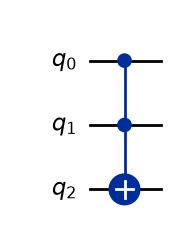

In [4]:
# Oráculo: Toffoli con controles q0 (a0), q1 (a1) y objetivo q2 (ancilla y)
tabla_and = {'00': '0', '01': '0', '10': '0', '11': '1'}     # a1a0 -> a1 AND a0

oraculo_and = QuantumCircuit(3, name='U_AND')
oraculo_and.ccx(0, 1, 2)
display(oraculo_and.draw('mpl'))

Entrada a1a0 = 00


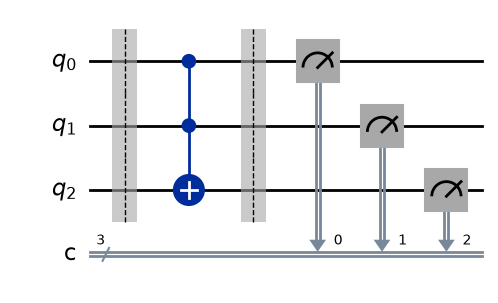

Entrada a1a0 = 01


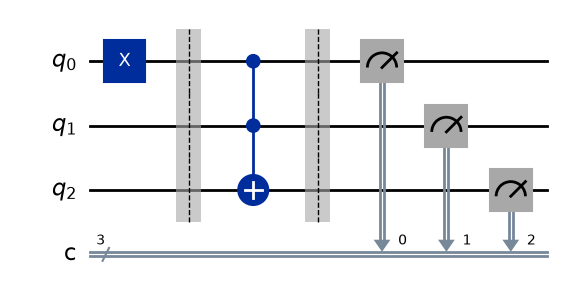

Entrada a1a0 = 10


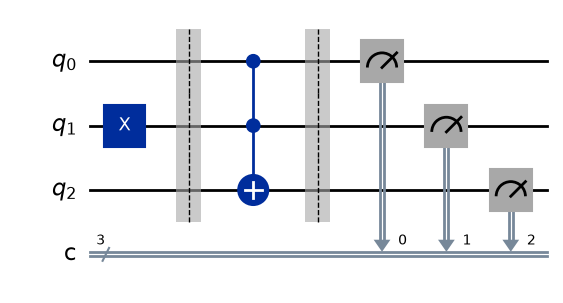

Entrada a1a0 = 11


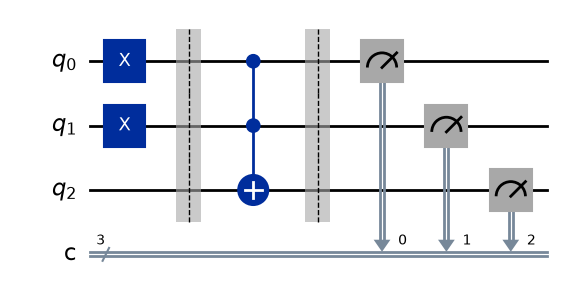

In [5]:
for x in tabla_and:
    print(f'Entrada a1a0 = {x}')
    display(circuito_entrada_clasica(oraculo_and, x).draw('mpl'))

In [6]:
filas_and = verificar_oraculo(oraculo_and, tabla_and, etiqueta='a1a0')
print()
comprobar_matriz(oraculo_and, tabla_and)
RESULTS['tables']['1.1'] = filas_and

|   a1a0 |   f(x) teórica |   f(x) simulada |   x tras U_f |   Probabilidad | Estado   |
|--------|----------------|-----------------|--------------|----------------|----------|
|     00 |              0 |               0 |           00 |              1 | OK       |
|     01 |              0 |               0 |           01 |              1 | OK       |
|     10 |              0 |               0 |           10 |              1 | OK       |
|     11 |              1 |               1 |           11 |              1 | OK       |

4/4 entradas correctas -> el oráculo es correcto

Matriz del circuito = matriz teórica de U_f : True
U_f es su propio inverso (U_f^2 = I)         : True


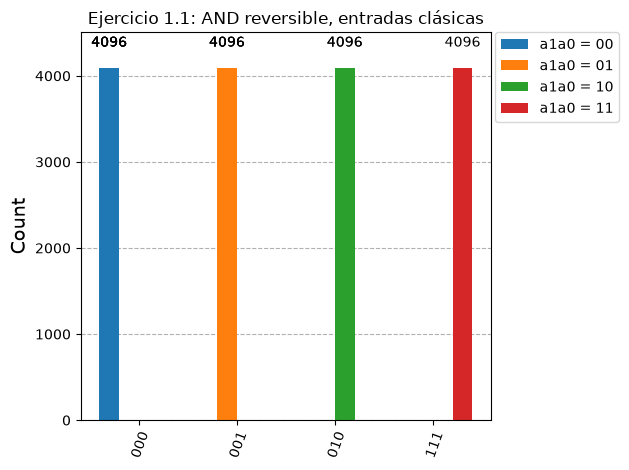

In [7]:
histograma_entradas_clasicas(oraculo_and, tabla_and, etiqueta='a1a0', titulo='Ejercicio 1.1: AND reversible, entradas clásicas')

### **Ejercicio 1.2. Paralelismo Cuántico**

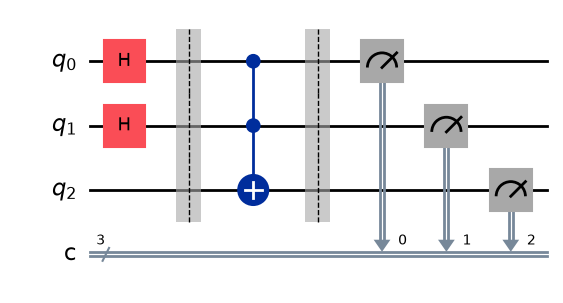

In [8]:
qc_sup_and = circuito_superposicion(oraculo_and, n_in=2)
display(qc_sup_and.draw('mpl'))

In [9]:
psi_and = Statevector(circuito_superposicion(oraculo_and, n_in=2, medir=False))
display(psi_and.draw('latex'))

probs_and = probs_teoricas(tabla_and)
sv_probs = probs_statevector(psi_and)
print('Probabilidades del vector de estado:', sv_probs)
print('Coinciden con la predicción analítica:',
      sv_probs.keys() == probs_and.keys() and all(np.isclose(sv_probs[k], probs_and[k]) for k in probs_and))

<IPython.core.display.Latex object>

Probabilidades del vector de estado: {'000': 0.2499999999999999, '001': 0.2499999999999999, '010': 0.2499999999999999, '111': 0.2499999999999999}
Coinciden con la predicción analítica: True


|   y a1 a0 |   P teórica |   P simulada |
|-----------|-------------|--------------|
|       000 |      0.2500 |       0.2507 |
|       001 |      0.2500 |       0.2483 |
|       010 |      0.2500 |       0.2524 |
|       111 |      0.2500 |       0.2485 |

Resultados fuera del soporte teórico: ninguno
Test chi^2 frente a la predicción: p-valor = 0.979 (compatible con la teoría al 5 %)


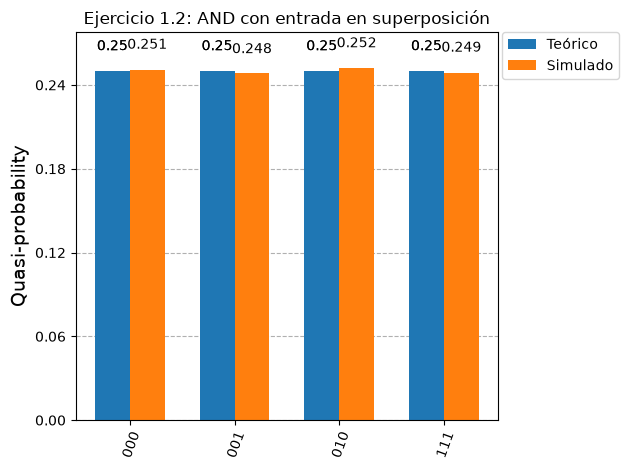

In [10]:
counts_sup_and = simular(qc_sup_and)
comparar_con_teoria(counts_sup_and, probs_and,
                    cabecera=['y a1 a0', 'P teórica', 'P simulada'],
                    titulo='Ejercicio 1.2: AND con entrada en superposición')

In [11]:
_, memoria = simular(qc_sup_and, n_shots=shots, memory=True)
print('Primeros 8 disparos individuales (y a1 a0):', memoria[:8])

n_filas = len(tabla_and)
longitudes = disparos_hasta_tabla_completa(memoria, n_filas)
teoria = n_filas * sum(1 / k for k in range(1, n_filas + 1))
print(f'Disparos necesarios para observar las {n_filas} filas: '
      f'media simulada = {np.mean(longitudes):.2f} | teoría n·H_n = {teoria:.2f} '
      f'| mín = {min(longitudes)}, máx = {max(longitudes)}')

Primeros 8 disparos individuales (y a1 a0): ['111', '000', '000', '010', '000', '010', '000', '001']
Disparos necesarios para observar las 4 filas: media simulada = 8.63 | teoría n·H_n = 8.33 | mín = 4, máx = 29


Cada ejecución de 1 disparo devuelve UNA sola fila (y a1 a0) elegida al azar:
|   Ejecución |   Fila obtenida |   Filas distintas acumuladas (de 4) |
|-------------|-----------------|-------------------------------------|
|           1 |             000 |                                   1 |
|           2 |             111 |                                   2 |
|           3 |             111 |                                   2 |
|           4 |             111 |                                   2 |
|           5 |             010 |                                   3 |
|           6 |             000 |                                   3 |
|           7 |             111 |                                   3 |
|           8 |             000 |                                   3 |
|           9 |             111 |                                   3 |
|          10 |             010 |                                   3 |

En una tanda de 40 disparos se completan las 4 filas en e

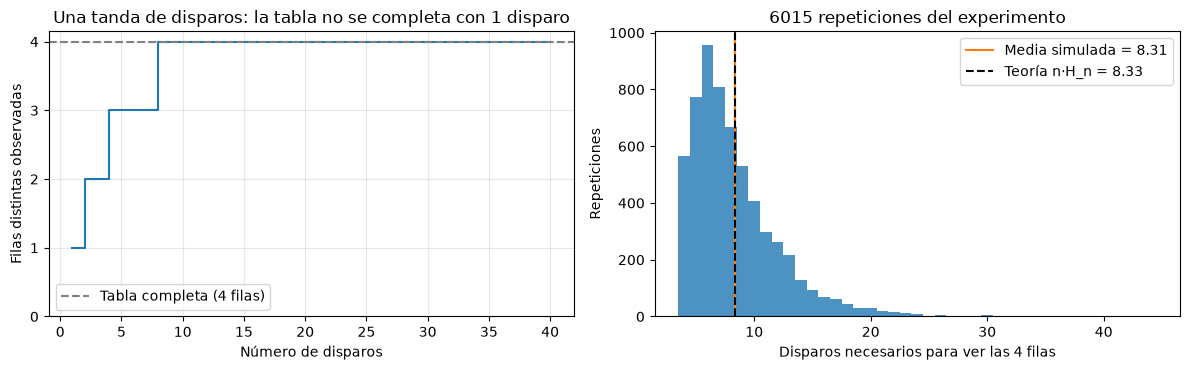

Mínimo posible = 4 disparos (nunca menos). Con exactamente 4 disparos solo se obtiene la tabla completa en el 9.4 % de los casos (teoría 4!/4^4 = 9.4 %).
Con 1 disparo: P(ver las 4 filas) = 0.


In [12]:
# ------------------------------------------------------------------
# Experimento: ¿se puede obtener la tabla de verdad con UN solo disparo?
# ------------------------------------------------------------------
qc_t = transpile(qc_sup_and, sim)

# (a) 10 ejecuciones independientes de 1 disparo (semilla distinta en cada una)
unico = [next(iter(sim.run(qc_t, shots=1, seed_simulator=1000 + s).result().get_counts())) for s in range(10)]
print('Cada ejecución de 1 disparo devuelve UNA sola fila (y a1 a0) elegida al azar:')
print(tabulate([[s + 1, r, len(set(unico[:s + 1]))] for s, r in enumerate(unico)],
               headers=['Ejecución', 'Fila obtenida', 'Filas distintas acumuladas (de 4)'], tablefmt='github'))

# (b) Disparos sucesivos: cuántas filas distintas se han visto tras k disparos
_, mem = simular(qc_sup_and, n_shots=40, memory=True)
vistas = [len(set(mem[:k])) for k in range(1, len(mem) + 1)]
k_completa = next((k for k, v in enumerate(vistas, 1) if v == 4), None)
print(f'\nEn una tanda de 40 disparos se completan las 4 filas en el disparo nº {k_completa}')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].step(range(1, len(vistas) + 1), vistas, where='post')
ax[0].axhline(4, color='gray', ls='--', label='Tabla completa (4 filas)')
ax[0].set_xlabel('Número de disparos'); ax[0].set_ylabel('Filas distintas observadas')
ax[0].set_yticks(range(0, 5)); ax[0].grid(alpha=0.3); ax[0].legend()
ax[0].set_title('Una tanda de disparos: la tabla no se completa con 1 disparo')

# (c) Repitiendo el experimento muchas veces: disparos necesarios para ver las 4 filas
_, mem_largo = simular(qc_sup_and, n_shots=50000, memory=True)
longitudes = disparos_hasta_tabla_completa(mem_largo, len(tabla_and))
teoria = len(tabla_and) * sum(1 / k for k in range(1, len(tabla_and) + 1))   # n·H_n = 25/3
ax[1].hist(longitudes, bins=np.arange(3.5, max(longitudes) + 1.5), color='tab:blue', alpha=0.8)
ax[1].axvline(np.mean(longitudes), color='tab:orange', label=f'Media simulada = {np.mean(longitudes):.2f}')
ax[1].axvline(teoria, color='k', ls='--', label=f'Teoría n·H_n = {teoria:.2f}')
ax[1].set_xlabel('Disparos necesarios para ver las 4 filas'); ax[1].set_ylabel('Repeticiones')
ax[1].legend(); ax[1].set_title(f'{len(longitudes)} repeticiones del experimento')
plt.tight_layout(); plt.show()

p1 = np.mean([l == 4 for l in longitudes])
print(f'Mínimo posible = 4 disparos (nunca menos). Con exactamente 4 disparos solo se obtiene la tabla '
      f'completa en el {100 * p1:.1f} % de los casos (teoría 4!/4^4 = {100 * 24 / 256:.1f} %).')
print('Con 1 disparo: P(ver las 4 filas) = 0.')

### **Ejercicio 1.3. Puerta XOR reversible**

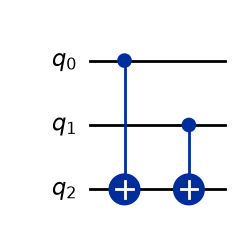

In [13]:
tabla_xor = {'00': '0', '01': '1', '10': '1', '11': '0'}     # a1a0 -> a1 XOR a0

oraculo_xor = QuantumCircuit(3, name='U_XOR')
oraculo_xor.cx(0, 2)
oraculo_xor.cx(1, 2)
display(oraculo_xor.draw('mpl'))

**(1.1 para XOR) Entradas clásicas**

Entrada a1a0 = 00


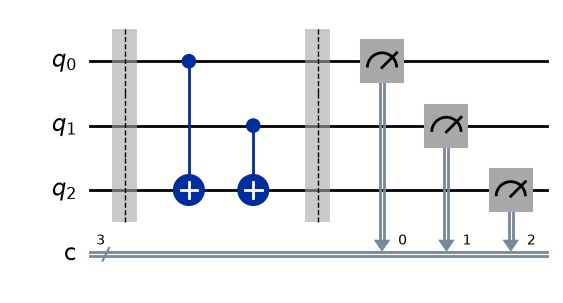

Entrada a1a0 = 01


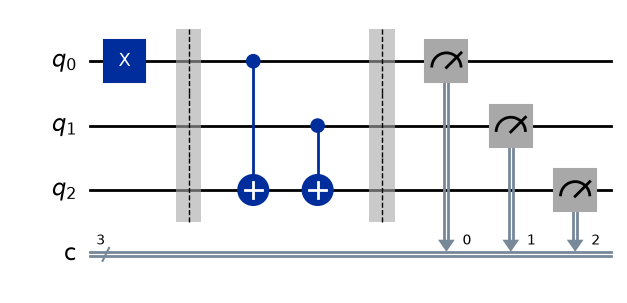

Entrada a1a0 = 10


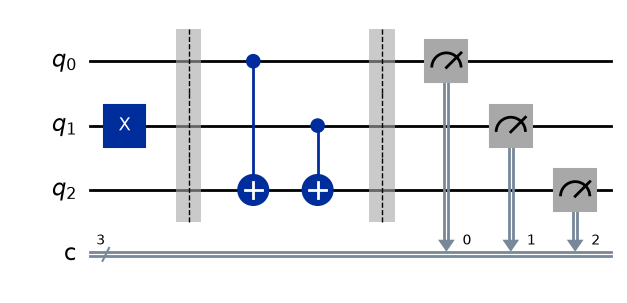

Entrada a1a0 = 11


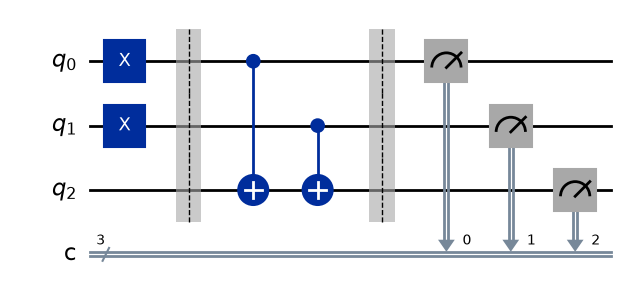

In [14]:
for x in tabla_xor:
    print(f'Entrada a1a0 = {x}')
    display(circuito_entrada_clasica(oraculo_xor, x).draw('mpl'))

In [15]:
filas_xor = verificar_oraculo(oraculo_xor, tabla_xor, etiqueta='a1a0')
print()
comprobar_matriz(oraculo_xor, tabla_xor)
RESULTS['tables']['1.3'] = filas_xor

|   a1a0 |   f(x) teórica |   f(x) simulada |   x tras U_f |   Probabilidad | Estado   |
|--------|----------------|-----------------|--------------|----------------|----------|
|     00 |              0 |               0 |           00 |              1 | OK       |
|     01 |              1 |               1 |           01 |              1 | OK       |
|     10 |              1 |               1 |           10 |              1 | OK       |
|     11 |              0 |               0 |           11 |              1 | OK       |

4/4 entradas correctas -> el oráculo es correcto

Matriz del circuito = matriz teórica de U_f : True
U_f es su propio inverso (U_f^2 = I)         : True


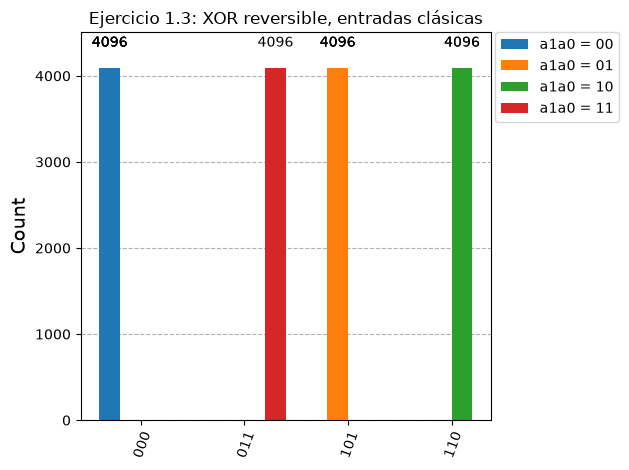

In [16]:
histograma_entradas_clasicas(oraculo_xor, tabla_xor, etiqueta='a1a0', titulo='Ejercicio 1.3: XOR reversible, entradas clásicas')

**(1.2 para XOR) Entrada en superposición**

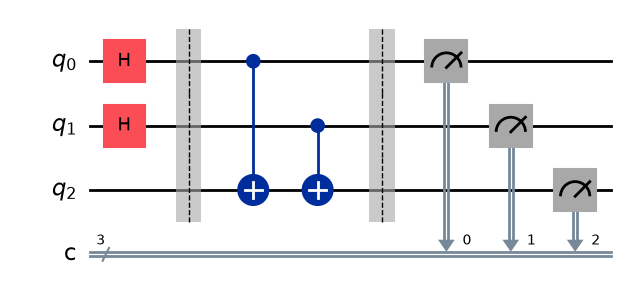

<IPython.core.display.Latex object>

Coinciden Statevector y predicción analítica: True


In [17]:
qc_sup_xor = circuito_superposicion(oraculo_xor, n_in=2)
display(qc_sup_xor.draw('mpl'))

psi_xor = Statevector(circuito_superposicion(oraculo_xor, n_in=2, medir=False))
display(psi_xor.draw('latex'))

probs_xor = probs_teoricas(tabla_xor)
sv_probs = probs_statevector(psi_xor)
print('Coinciden Statevector y predicción analítica:',
      sv_probs.keys() == probs_xor.keys() and all(np.isclose(sv_probs[k], probs_xor[k]) for k in probs_xor))

|   y a1 a0 |   P teórica |   P simulada |
|-----------|-------------|--------------|
|       000 |      0.2500 |       0.2512 |
|       011 |      0.2500 |       0.2568 |
|       101 |      0.2500 |       0.2456 |
|       110 |      0.2500 |       0.2463 |

Resultados fuera del soporte teórico: ninguno
Test chi^2 frente a la predicción: p-valor = 0.723 (compatible con la teoría al 5 %)


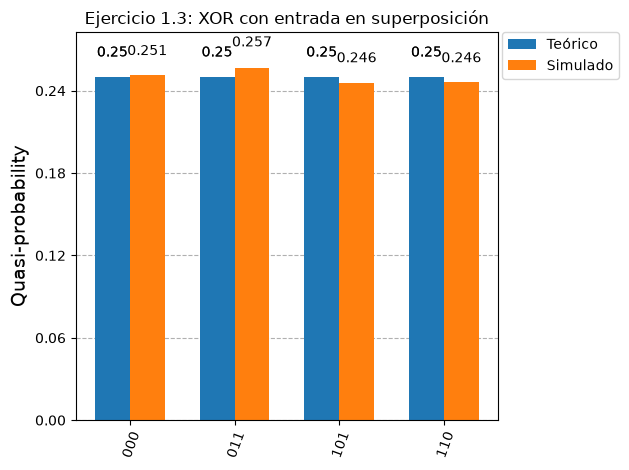


Disparos necesarios para observar las 4 filas: media simulada = 8.35 (teoría 25/3 = 8.33)


In [18]:
counts_sup_xor = simular(qc_sup_xor)
comparar_con_teoria(counts_sup_xor, probs_xor,
                    cabecera=['y a1 a0', 'P teórica', 'P simulada'],
                    titulo='Ejercicio 1.3: XOR con entrada en superposición')

_, memoria = simular(qc_sup_xor, n_shots=20000, memory=True)
longitudes = disparos_hasta_tabla_completa(memoria, len(tabla_xor))
print(f'\nDisparos necesarios para observar las 4 filas: media simulada = {np.mean(longitudes):.2f} (teoría 25/3 = {25/3:.2f})')

Cada ejecución de 1 disparo devuelve UNA sola fila (y a1 a0) elegida al azar:
|   Ejecución |   Fila obtenida |   Filas distintas acumuladas (de 4) |
|-------------|-----------------|-------------------------------------|
|           1 |             110 |                                   1 |
|           2 |             011 |                                   2 |
|           3 |             101 |                                   3 |
|           4 |             011 |                                   3 |
|           5 |             011 |                                   3 |
|           6 |             110 |                                   3 |
|           7 |             011 |                                   3 |
|           8 |             000 |                                   4 |
|           9 |             011 |                                   4 |
|          10 |             101 |                                   4 |

En una tanda de 40 disparos se completan las 4 filas en e

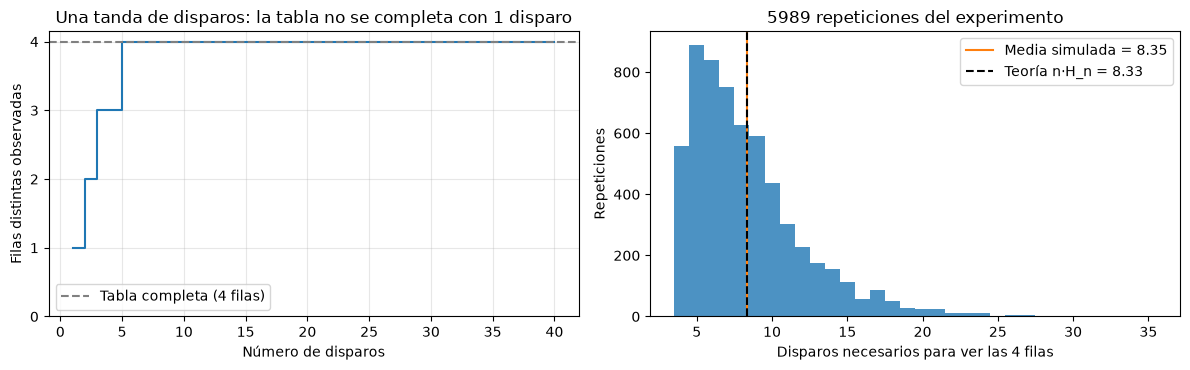

Mínimo posible = 4 disparos (nunca menos). Con exactamente 4 disparos solo se obtiene la tabla completa en el 9.3 % de los casos (teoría 4!/4^4 = 9.4 %).
Con 1 disparo: P(ver las 4 filas) = 0.


In [19]:
# ------------------------------------------------------------------
# Experimento: ¿se puede obtener la tabla de verdad del XOR con UN solo disparo?
# ------------------------------------------------------------------
qc_t = transpile(qc_sup_xor, sim)

# (a) 10 ejecuciones independientes de 1 disparo (semilla distinta en cada una)
unico = [next(iter(sim.run(qc_t, shots=1, seed_simulator=1000 + s).result().get_counts())) for s in range(10)]
print('Cada ejecución de 1 disparo devuelve UNA sola fila (y a1 a0) elegida al azar:')
print(tabulate([[s + 1, r, len(set(unico[:s + 1]))] for s, r in enumerate(unico)],
               headers=['Ejecución', 'Fila obtenida', 'Filas distintas acumuladas (de 4)'], tablefmt='github'))

# (b) Disparos sucesivos: cuántas filas distintas se han visto tras k disparos
_, mem = simular(qc_sup_xor, n_shots=40, memory=True)
vistas = [len(set(mem[:k])) for k in range(1, len(mem) + 1)]
k_completa = next((k for k, v in enumerate(vistas, 1) if v == 4), None)
print(f'\nEn una tanda de 40 disparos se completan las 4 filas en el disparo nº {k_completa}')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].step(range(1, len(vistas) + 1), vistas, where='post')
ax[0].axhline(4, color='gray', ls='--', label='Tabla completa (4 filas)')
ax[0].set_xlabel('Número de disparos'); ax[0].set_ylabel('Filas distintas observadas')
ax[0].set_yticks(range(0, 5)); ax[0].grid(alpha=0.3); ax[0].legend()
ax[0].set_title('Una tanda de disparos: la tabla no se completa con 1 disparo')

# (c) Repitiendo el experimento muchas veces: disparos necesarios para ver las 4 filas
_, mem_largo = simular(qc_sup_xor, n_shots=50000, memory=True)
longitudes = disparos_hasta_tabla_completa(mem_largo, len(tabla_xor))
teoria = len(tabla_xor) * sum(1 / k for k in range(1, len(tabla_xor) + 1))   # n·H_n = 25/3
ax[1].hist(longitudes, bins=np.arange(3.5, max(longitudes) + 1.5), color='tab:blue', alpha=0.8)
ax[1].axvline(np.mean(longitudes), color='tab:orange', label=f'Media simulada = {np.mean(longitudes):.2f}')
ax[1].axvline(teoria, color='k', ls='--', label=f'Teoría n·H_n = {teoria:.2f}')
ax[1].set_xlabel('Disparos necesarios para ver las 4 filas'); ax[1].set_ylabel('Repeticiones')
ax[1].legend(); ax[1].set_title(f'{len(longitudes)} repeticiones del experimento')
plt.tight_layout(); plt.show()

p1 = np.mean([l == 4 for l in longitudes])
print(f'Mínimo posible = 4 disparos (nunca menos). Con exactamente 4 disparos solo se obtiene la tabla '
      f'completa en el {100 * p1:.1f} % de los casos (teoría 4!/4^4 = {100 * 24 / 256:.1f} %).')
print('Con 1 disparo: P(ver las 4 filas) = 0.')

### **Ejercico 1.4. Oráculo de 3 bits con puertas multicontroladas**

Minitérminos (x2x1x0) con f(x) = 1: ['001', '101', '111']
  001: controles sobre |0> en q1, q2
  101: controles sobre |0> en q1
  111: controles sobre |0> en ninguno


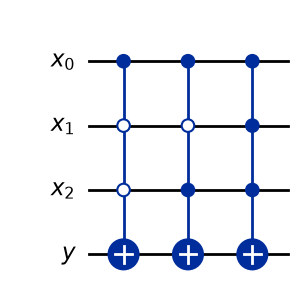

In [20]:
tabla_1_4 = {'000': '0', '001': '1', '010': '0', '011': '0',
             '100': '0', '101': '1', '110': '0', '111': '1'}      # x2x1x0 -> f(x)

minterminos = [x for x, fx in tabla_1_4.items() if fx == '1']
print('Minitérminos (x2x1x0) con f(x) = 1:', minterminos)
for x in minterminos:
    ceros = [f'q{j}' for j, b in enumerate(x[::-1]) if b == '0']
    print(f'  {x}: controles sobre |0> en {", ".join(ceros) if ceros else "ninguno"}')

oraculo_1_4 = oraculo_booleano(tabla_1_4)
display(oraculo_1_4.draw('mpl'))

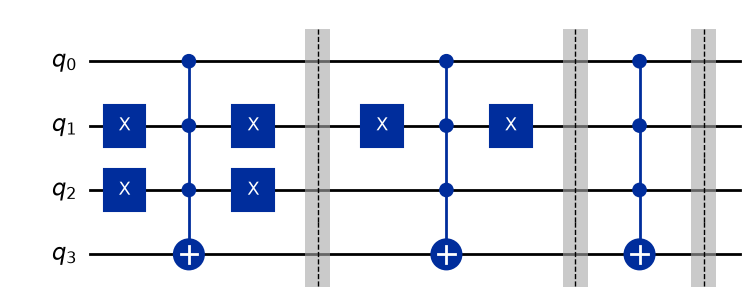

Equivalente a la versión con ctrl_state: True


In [21]:
def oraculo_con_X(tabla):
    n_in = len(next(iter(tabla)))
    qc = QuantumCircuit(n_in + 1, name='U_f (con X)')
    for x, fx in tabla.items():
        if fx == '1':
            ceros = [j for j, b in enumerate(x[::-1]) if b == '0']
            if ceros:
                qc.x(ceros)
            qc.mcx(list(range(n_in)), n_in)
            if ceros:
                qc.x(ceros)
            qc.barrier()
    return qc

oraculo_1_4_x = oraculo_con_X(tabla_1_4)
display(oraculo_1_4_x.draw('mpl'))
print('Equivalente a la versión con ctrl_state:', Operator(oraculo_1_4).equiv(Operator(oraculo_1_4_x)))

Ejemplo de circuito de prueba, entrada x2x1x0 = 101:


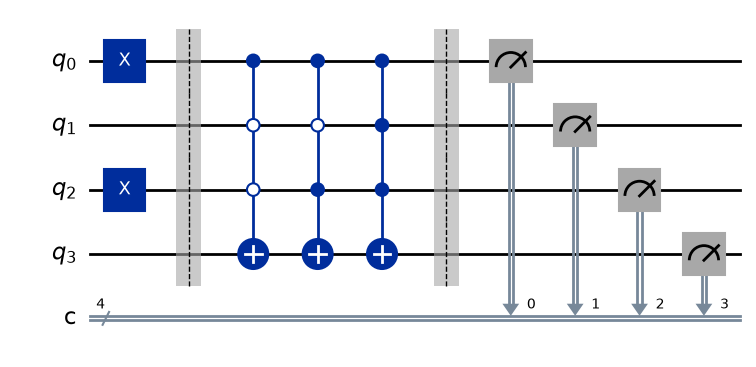

|   x2x1x0 |   f(x) teórica |   f(x) simulada |   x tras U_f |   Probabilidad | Estado   |
|----------|----------------|-----------------|--------------|----------------|----------|
|      000 |              0 |               0 |          000 |              1 | OK       |
|      001 |              1 |               1 |          001 |              1 | OK       |
|      010 |              0 |               0 |          010 |              1 | OK       |
|      011 |              0 |               0 |          011 |              1 | OK       |
|      100 |              0 |               0 |          100 |              1 | OK       |
|      101 |              1 |               1 |          101 |              1 | OK       |
|      110 |              0 |               0 |          110 |              1 | OK       |
|      111 |              1 |               1 |          111 |              1 | OK       |

8/8 entradas correctas -> el oráculo es correcto

Matriz del circuito = matriz teórica de

In [22]:
print('Ejemplo de circuito de prueba, entrada x2x1x0 = 101:')
display(circuito_entrada_clasica(oraculo_1_4, '101').draw('mpl'))

filas_1_4 = verificar_oraculo(oraculo_1_4, tabla_1_4, etiqueta='x2x1x0')
print()
comprobar_matriz(oraculo_1_4, tabla_1_4)
RESULTS['tables']['1.4'] = filas_1_4

### **Ejercicio 1.5. Oráculo de 4 bits de entrada y 4 de salida**

Unos en la tabla: 32 | puertas multicontroladas en el circuito: 32


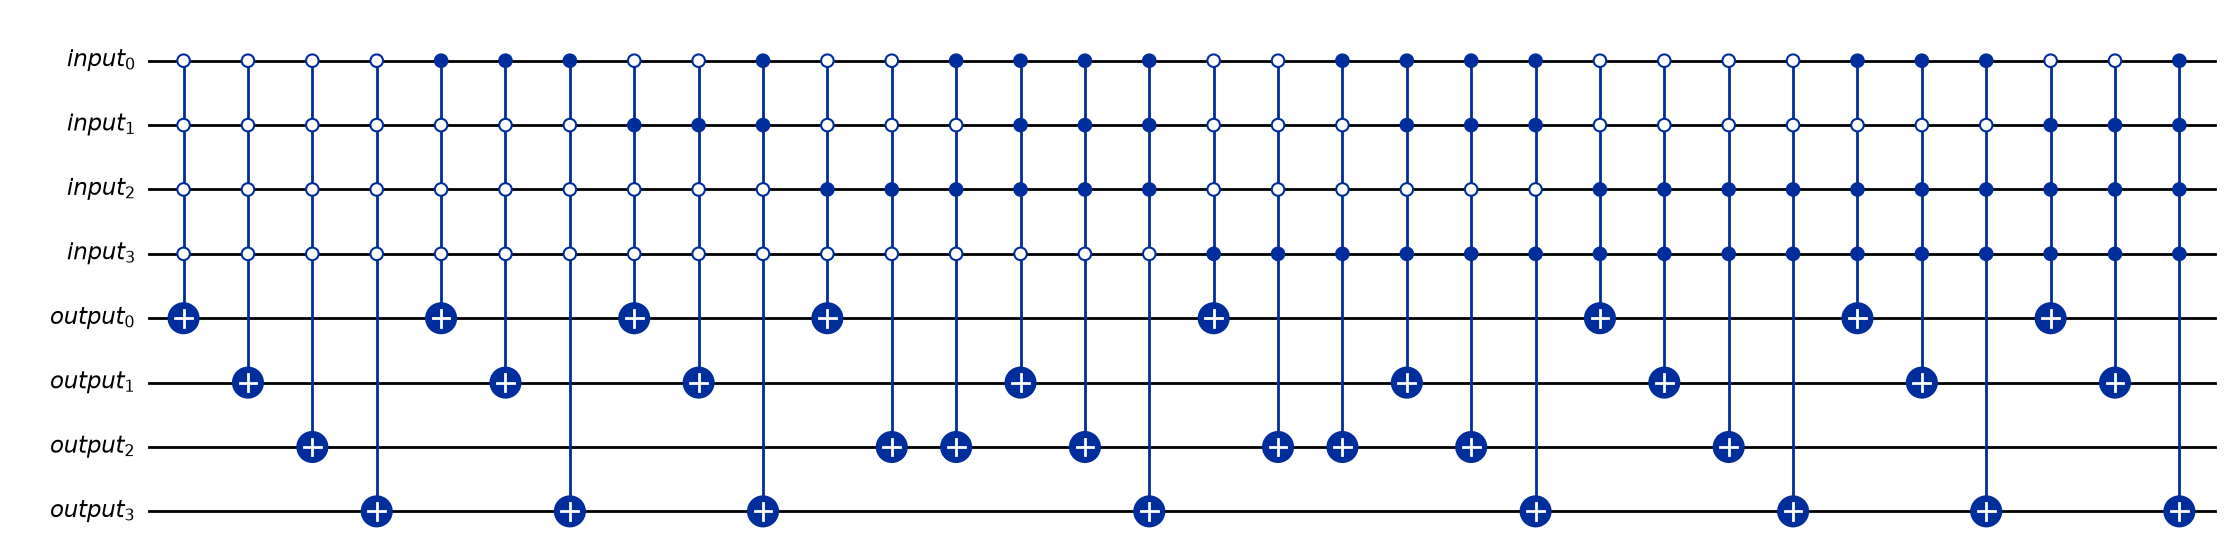

In [23]:
tabla_1_5 = {'0000': '1111', '0001': '1011', '0010': '0011', '0011': '1000',
             '0100': '0101', '0101': '0100', '0110': '0000', '0111': '1110',
             '1000': '0101', '1001': '0100', '1010': '0000', '1011': '1110',
             '1100': '1111', '1101': '1011', '1110': '0011', '1111': '1000'}   # x3x2x1x0 -> f3f2f1f0

oraculo_1_5 = oraculo_booleano(tabla_1_5, nombre_in='input', nombre_out='output')

unos_tabla = sum(fx.count('1') for fx in tabla_1_5.values())
print(f'Unos en la tabla: {unos_tabla} | puertas multicontroladas en el circuito: {oraculo_1_5.size()}')
display(oraculo_1_5.draw('mpl', fold=40))

**Simulación de las 16 entradas** (tabla simulada junto a la teórica):

In [24]:
filas_1_5 = verificar_oraculo(oraculo_1_5, tabla_1_5, etiqueta='x3x2x1x0')
print()
comprobar_matriz(oraculo_1_5, tabla_1_5)
RESULTS['tables']['1.5'] = filas_1_5

|   x3x2x1x0 |   f(x) teórica |   f(x) simulada |   x tras U_f |   Probabilidad | Estado   |
|------------|----------------|-----------------|--------------|----------------|----------|
|       0000 |           1111 |            1111 |         0000 |              1 | OK       |
|       0001 |           1011 |            1011 |         0001 |              1 | OK       |
|       0010 |           0011 |            0011 |         0010 |              1 | OK       |
|       0011 |           1000 |            1000 |         0011 |              1 | OK       |
|       0100 |           0101 |            0101 |         0100 |              1 | OK       |
|       0101 |           0100 |            0100 |         0101 |              1 | OK       |
|       0110 |           0000 |            0000 |         0110 |              1 | OK       |
|       0111 |           1110 |            1110 |         0111 |              1 | OK       |
|       1000 |           0101 |            0101 |         1000 |      

### **Ejercicio 1.6. Función lineal $f(x) = a\cdot x$**

Entradas con f(x) = 1: 16 de 32


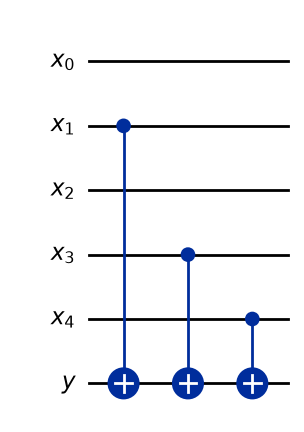

In [25]:
def oraculo_lineal(a, nombre_in='x', nombre_out='y'):
    """Oráculo de f(x) = a·x (mod 2). a = 'a_{n-1}...a_0'; el bit a_i controla un CNOT desde q_i a la ancilla."""
    n = len(a)
    entrada = QuantumRegister(n, nombre_in)
    salida = QuantumRegister(1, nombre_out)
    qc = QuantumCircuit(entrada, salida, name=f'U_f (a={a})')
    for i, bit in enumerate(a[::-1]):
        if bit == '1':
            qc.cx(entrada[i], salida[0])
    return qc

def tabla_lineal(a):
    """Tabla de verdad teórica de f(x) = a·x (mod 2): paridad de los bits de a AND x."""
    n = len(a)
    return {format(x, f'0{n}b'): str(bin(x & int(a, 2)).count('1') % 2) for x in range(2 ** n)}

a_1_6 = '11010'
oraculo_1_6 = oraculo_lineal(a_1_6)
tabla_1_6 = tabla_lineal(a_1_6)
print('Entradas con f(x) = 1:', sum(v == '1' for v in tabla_1_6.values()), 'de', len(tabla_1_6))
display(oraculo_1_6.draw('mpl'))

In [26]:
filas_1_6 = verificar_oraculo(oraculo_1_6, tabla_1_6, etiqueta='x4x3x2x1x0')
print()
comprobar_matriz(oraculo_1_6, tabla_1_6)
RESULTS['tables']['1.6'] = filas_1_6

|   x4x3x2x1x0 |   f(x) teórica |   f(x) simulada |   x tras U_f |   Probabilidad | Estado   |
|--------------|----------------|-----------------|--------------|----------------|----------|
|        00000 |              0 |               0 |        00000 |              1 | OK       |
|        00001 |              0 |               0 |        00001 |              1 | OK       |
|        00010 |              1 |               1 |        00010 |              1 | OK       |
|        00011 |              1 |               1 |        00011 |              1 | OK       |
|        00100 |              0 |               0 |        00100 |              1 | OK       |
|        00101 |              0 |               0 |        00101 |              1 | OK       |
|        00110 |              1 |               1 |        00110 |              1 | OK       |
|        00111 |              1 |               1 |        00111 |              1 | OK       |
|        01000 |              1 |               1 

## **Bloque 2. Retroceso de fase y oráculos de fase**

In [27]:
def evolucion(n, pasos):
    """Aplica uno a uno los pasos (etiqueta, funcion(qc)) a un circuito de n qubits sin medidas
    y guarda el Statevector tras cada uno. Devuelve (circuito, [(etiqueta, Statevector)])."""
    qc = QuantumCircuit(n)
    salida = [('Estado inicial', Statevector(qc))]
    for etiqueta, fn in pasos:
        fn(qc)
        salida.append((etiqueta, Statevector(qc)))
    return qc, salida


def vector_bloch(psi, qubit):
    """(<X>, <Y>, <Z>) del qubit indicado (vale también para qubits entrelazados)."""
    return tuple(float(np.real(psi.expectation_value(Pauli(p), [qubit]))) for p in 'XYZ')


def mostrar_evolucion(salida, bloch=True):
    """Muestra, para cada punto, el estado en notación de Dirac y (opcional) las esferas de Bloch."""
    for etiqueta, psi in salida:
        print(etiqueta)
        display(psi.draw('latex'))
        if bloch:
            display(plot_bloch_multivector(psi, title=etiqueta))


def tabla_bloch(salida, qubits):
    filas = []
    for etiqueta, psi in salida:
        fila = [etiqueta]
        for q in qubits:
            x, y, z = vector_bloch(psi, q)
            fila.append(f'({x:+.3f}, {y:+.3f}, {z:+.3f})')
        filas.append(fila)
    print(tabulate(filas, headers=['Punto'] + [f'Bloch q{q} (x, y, z)' for q in qubits], tablefmt='github'))


def prob_q0_uno(counts):
    """P(q0 = 1) a partir de counts con cadena 'c1c0' (el bit de la derecha es q0)."""
    return sum(v for k, v in counts.items() if k[-1] == '1') / sum(counts.values())


### **Ejercicio 2.1. Retroceso con $CP(\pi/4)$**

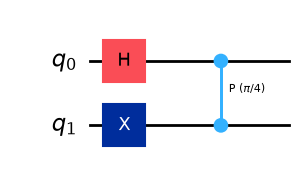

Estado inicial                             coincide con el cálculo a mano: True
Tras H(q0)                                 coincide con el cálculo a mano: True
Tras X(q1)                                 coincide con el cálculo a mano: True
Tras CP(pi/4), control q0 y objetivo q1    coincide con el cálculo a mano: True
Estado inicial


<IPython.core.display.Latex object>

Tras H(q0)


<IPython.core.display.Latex object>

Tras X(q1)


<IPython.core.display.Latex object>

Tras CP(pi/4), control q0 y objetivo q1


<IPython.core.display.Latex object>

In [28]:
s = 1 / np.sqrt(2)
pasos_21 = [('Tras H(q0)', lambda qc: qc.h(0)),
            ('Tras X(q1)', lambda qc: qc.x(1)),
            ('Tras CP(pi/4), control q0 y objetivo q1', lambda qc: qc.cp(np.pi / 4, 0, 1))]
qc_21, est_21 = evolucion(2, pasos_21)
display(qc_21.draw('mpl'))

# Estados calculados a mano, en el orden [|00>, |01>, |10>, |11>] = |q1 q0>
a_mano_21 = [np.array([1, 0, 0, 0]),
             np.array([s, s, 0, 0]),
             np.array([0, 0, s, s]),
             np.array([0, 0, s, s * np.exp(1j * np.pi / 4)])]
for (etiqueta, psi), v in zip(est_21, a_mano_21):
    print(f'{etiqueta:42s} coincide con el cálculo a mano: {np.allclose(psi.data, v)}')
mostrar_evolucion(est_21, bloch=False)

**b) Esfera de Bloch del estado final** e identificación del qubit donde aparece la fase:

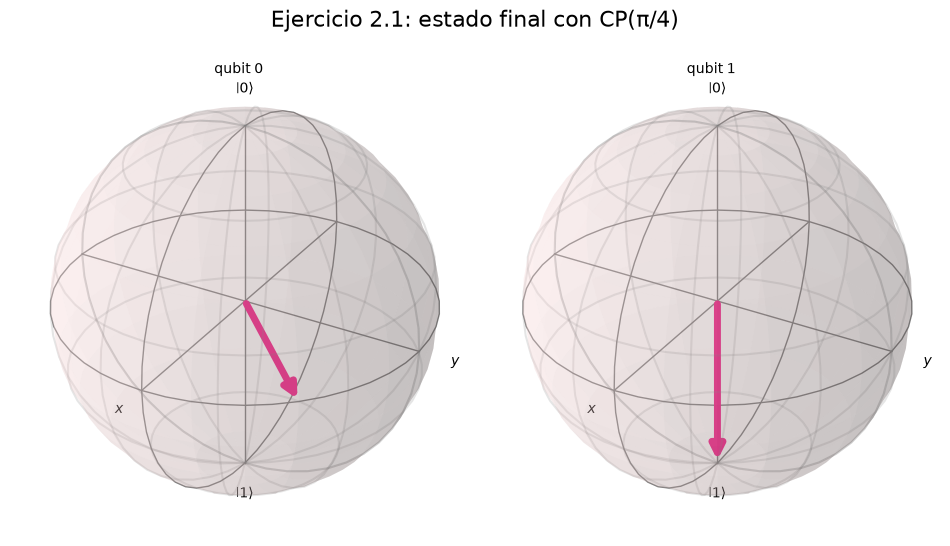

| Punto                                   | Bloch q0 (x, y, z)       | Bloch q1 (x, y, z)       |
|-----------------------------------------|--------------------------|--------------------------|
| Estado inicial                          | (+0.000, +0.000, +1.000) | (+0.000, +0.000, +1.000) |
| Tras H(q0)                              | (+1.000, +0.000, +0.000) | (+0.000, +0.000, +1.000) |
| Tras X(q1)                              | (+1.000, +0.000, +0.000) | (+0.000, +0.000, -1.000) |
| Tras CP(pi/4), control q0 y objetivo q1 | (+0.707, +0.707, +0.000) | (+0.000, +0.000, -1.000) |

q0: azimut = atan2(y, x) = 0.7854 rad   (π/4 = 0.7854 rad)


In [29]:
psi_21 = est_21[-1][1]
display(plot_bloch_multivector(psi_21, title='Ejercicio 2.1: estado final con CP(π/4)'))
tabla_bloch(est_21, [0, 1])
x0, y0, z0 = vector_bloch(psi_21, 0)
print(f'\nq0: azimut = atan2(y, x) = {np.arctan2(y0, x0):.4f} rad   (π/4 = {np.pi/4:.4f} rad)')

**c) $P(\pi/4)$ sin control sobre $q_1$.** Ahora $q_1=|1\rangle$ simplemente se multiplica por $e^{i\pi/4}$ y el estado total es $e^{i\pi/4}\,|{+}\rangle_{q_0}|1\rangle_{q_1}$: una **fase global**.

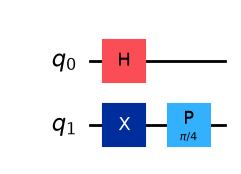

Factor entre el estado de después y el de antes de P(π/4): (0.7071+0.7071j)   (= e^(iπ/4) = (0.7071+0.7071j))
¿Mismo estado salvo fase global (Statevector.equiv)?      : True
| Punto                               | Bloch q0 (x, y, z)       | Bloch q1 (x, y, z)       |
|-------------------------------------|--------------------------|--------------------------|
| Estado inicial                      | (+0.000, +0.000, +1.000) | (+0.000, +0.000, +1.000) |
| Tras H(q0)                          | (+1.000, +0.000, +0.000) | (+0.000, +0.000, +1.000) |
| Tras X(q1)                          | (+1.000, +0.000, +0.000) | (+0.000, +0.000, -1.000) |
| Tras P(pi/4) sobre q1 (sin control) | (+1.000, +0.000, +0.000) | (+0.000, +0.000, -1.000) |


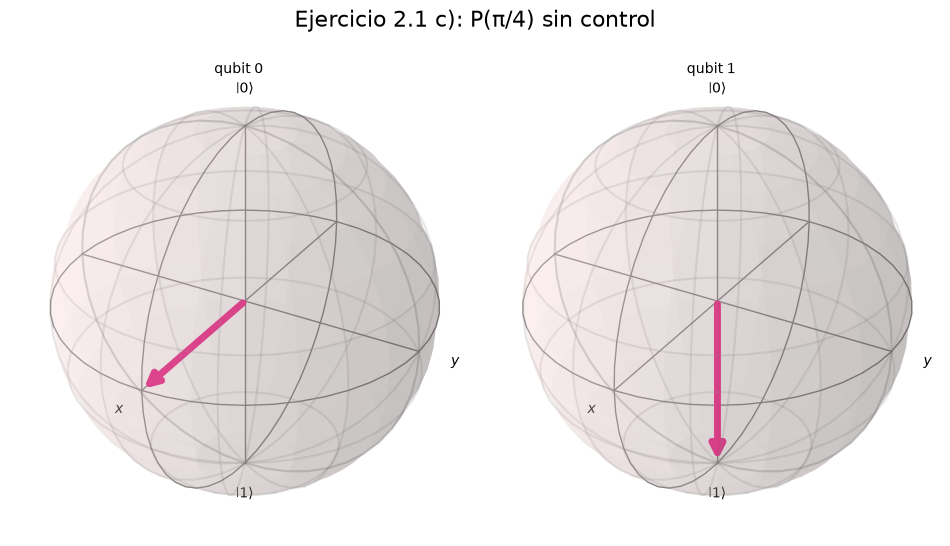

In [30]:
pasos_21c = [('Tras H(q0)', lambda qc: qc.h(0)),
             ('Tras X(q1)', lambda qc: qc.x(1)),
             ('Tras P(pi/4) sobre q1 (sin control)', lambda qc: qc.p(np.pi / 4, 1))]
qc_21c, est_21c = evolucion(2, pasos_21c)
display(qc_21c.draw('mpl'))

antes, despues = est_21c[2][1], est_21c[3][1]
i = np.argmax(np.abs(antes.data))
print('Factor entre el estado de después y el de antes de P(π/4):', np.round(despues.data[i] / antes.data[i], 4),
      f'  (= e^(iπ/4) = {np.round(np.exp(1j*np.pi/4), 4)})')
print('¿Mismo estado salvo fase global (Statevector.equiv)?      :', despues.equiv(antes))
tabla_bloch(est_21c, [0, 1])
display(plot_bloch_multivector(despues, title='Ejercicio 2.1 c): P(π/4) sin control'))

### **Ejercicio 2.2. Retroceso con CNOT**

Circuito: $H$ en $q_0$ y en $q_1$, $\mathrm{CNOT}(q_0\to q_1)$ y de nuevo $H$ en ambos.

**Cálculo a mano.**

- **a) $q_1=|+\rangle$.** $X|+\rangle=|+\rangle$, es decir, $|+\rangle$ es autovector de $X$ con autovalor $+1$. Por tanto $\mathrm{CNOT}\,|x\rangle|+\rangle=|x\rangle|+\rangle$ para $x=0,1$ y, por linealidad, $\mathrm{CNOT}\,|{+}{+}\rangle=|{+}{+}\rangle$: el CNOT **no altera el estado**. Tras las $H$ finales: $|00\rangle$.
- **b) $q_1=|-\rangle$.** $X|-\rangle=-|-\rangle$ (autovalor $-1$), luego $\mathrm{CNOT}\,|x\rangle|-\rangle=(-1)^x|x\rangle|-\rangle$ y $\mathrm{CNOT}\,|{+}{-}\rangle=|{-}{-}\rangle$: el autovalor $-1$ aparece como fase relativa en el control. Tras las $H$ finales: $|11\rangle$, y se mide $q_0=1$ con probabilidad 1.
- **c) $X$ en lugar de CNOT.** $X$ sobre $q_1$ no está controlada: con $|+\rangle$ no hace nada y con $|-\rangle$ solo introduce $-1$ **global**, así que $q_0$ siempre acaba en $|0\rangle$.

--- puerta = CX, q1 inicial = |+> ---


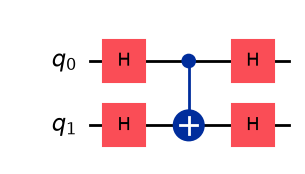

--- puerta = CX, q1 inicial = |-> ---


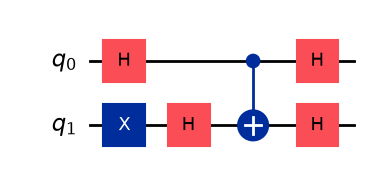

--- puerta = X, q1 inicial = |+> ---


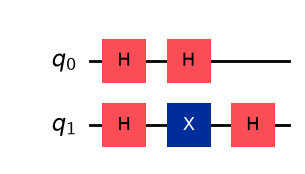

--- puerta = X, q1 inicial = |-> ---


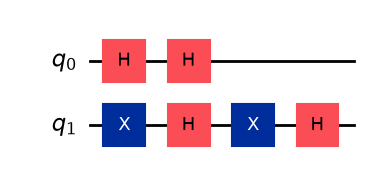


| Puerta   | q1 inicial   | Medida     |   Probabilidad | Estado final = a mano   |
|----------|--------------|------------|----------------|-------------------------|
| CX       | |+>          | q1 q0 = 00 |              1 | True                    |
| CX       | |->          | q1 q0 = 11 |              1 | True                    |
| X        | |+>          | q1 q0 = 00 |              1 | True                    |
| X        | |->          | q1 q0 = 10 |              1 | True                    |


In [31]:
def pasos_22(q1_menos, puerta):
    def preparar(qc):
        qc.h(0)
        if q1_menos:
            qc.x(1)
        qc.h(1)
    def compuerta(qc):
        if puerta == 'cx':
            qc.cx(0, 1)
        else:
            qc.x(1)
    def volver(qc):
        qc.h([0, 1])
    nombre_q1 = '|->' if q1_menos else '|+>'
    nombre_p = 'CNOT(q0->q1)' if puerta == 'cx' else 'X(q1)'
    return [(f'Tras preparar q0=|+>, q1={nombre_q1}', preparar),
            (f'Tras {nombre_p}', compuerta),
            ('Tras H en q0 y q1', volver)]

# Estados finales calculados a mano, orden [|00>,|01>,|10>,|11>] = |q1 q0>
final_mano_22 = {('cx', False): [1, 0, 0, 0],      # |00>
                 ('cx', True):  [0, 0, 0, 1],      # |11>
                 ('x',  False): [1, 0, 0, 0],      # |00>
                 ('x',  True):  [0, 0, -1, 0]}     # -|10>  (q1=1, q0=0, signo global)

casos_22 = [('cx', False), ('cx', True), ('x', False), ('x', True)]
filas_22, estados_22 = [], {}
for puerta, q1_menos in casos_22:
    qc_, est_ = evolucion(2, pasos_22(q1_menos, puerta))
    estados_22[(puerta, q1_menos)] = est_
    print(f'--- puerta = {puerta.upper()}, q1 inicial = {"|->" if q1_menos else "|+>"} ---')
    display(qc_.draw('mpl'))
    qc_med = QuantumCircuit(2, 2)
    qc_med.compose(qc_, inplace=True)
    qc_med.measure([0, 1], [0, 1])
    counts_ = simular(qc_med)
    medido = max(counts_, key=counts_.get)                    # 'q1 q0'
    filas_22.append([puerta.upper(), '|->' if q1_menos else '|+>', 'q1 q0 = ' + medido, counts_[medido] / shots,
                     np.allclose(est_[-1][1].data, final_mano_22[(puerta, q1_menos)])])
print()
print(tabulate(filas_22, headers=['Puerta', 'q1 inicial', 'Medida', 'Probabilidad', 'Estado final = a mano'], tablefmt='github'))

==== CNOT con q1 = |+> ====
Estado inicial


<IPython.core.display.Latex object>

Tras preparar q0=|+>, q1=|+>


<IPython.core.display.Latex object>

Tras CNOT(q0->q1)


<IPython.core.display.Latex object>

Tras H en q0 y q1


<IPython.core.display.Latex object>

| Punto                        | Bloch q0 (x, y, z)       | Bloch q1 (x, y, z)       |
|------------------------------|--------------------------|--------------------------|
| Estado inicial               | (+0.000, +0.000, +1.000) | (+0.000, +0.000, +1.000) |
| Tras preparar q0=|+>, q1=|+> | (+1.000, +0.000, +0.000) | (+1.000, +0.000, +0.000) |
| Tras CNOT(q0->q1)            | (+1.000, +0.000, +0.000) | (+1.000, +0.000, +0.000) |
| Tras H en q0 y q1            | (+0.000, +0.000, +1.000) | (+0.000, +0.000, +1.000) |


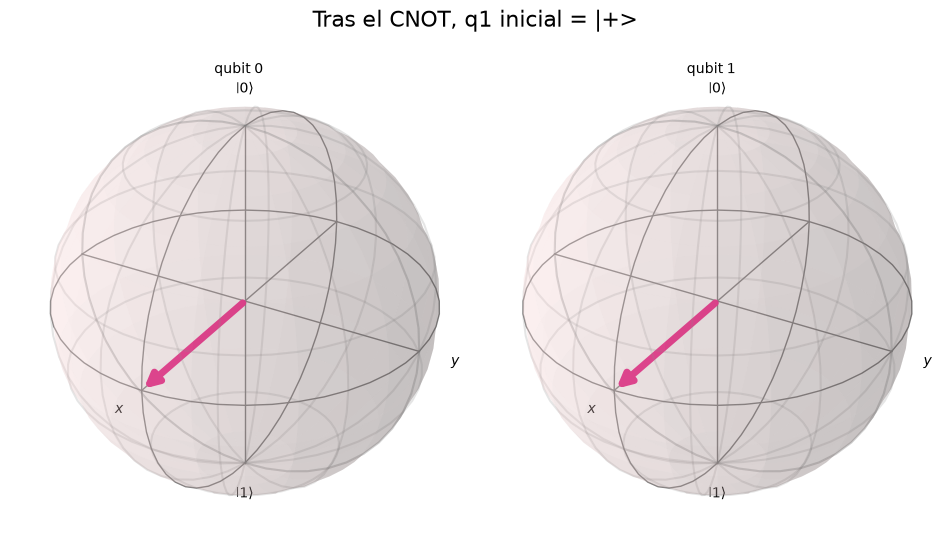

==== CNOT con q1 = |-> ====
Estado inicial


<IPython.core.display.Latex object>

Tras preparar q0=|+>, q1=|->


<IPython.core.display.Latex object>

Tras CNOT(q0->q1)


<IPython.core.display.Latex object>

Tras H en q0 y q1


<IPython.core.display.Latex object>

| Punto                        | Bloch q0 (x, y, z)       | Bloch q1 (x, y, z)       |
|------------------------------|--------------------------|--------------------------|
| Estado inicial               | (+0.000, +0.000, +1.000) | (+0.000, +0.000, +1.000) |
| Tras preparar q0=|+>, q1=|-> | (+1.000, +0.000, +0.000) | (-1.000, +0.000, +0.000) |
| Tras CNOT(q0->q1)            | (-1.000, +0.000, +0.000) | (-1.000, +0.000, +0.000) |
| Tras H en q0 y q1            | (+0.000, +0.000, -1.000) | (+0.000, +0.000, -1.000) |


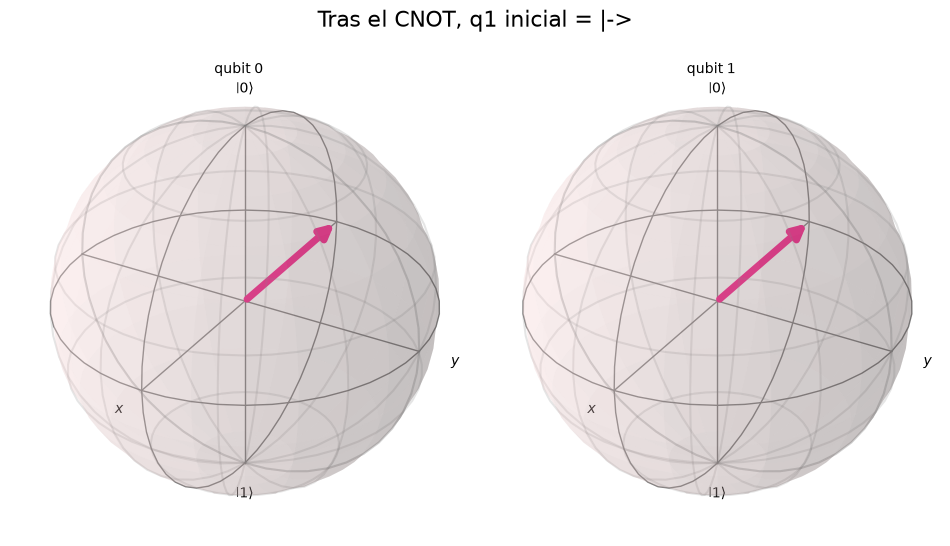

In [32]:
for q1_menos in (False, True):
    est_ = estados_22[('cx', q1_menos)]
    print(f'==== CNOT con q1 = {"|->" if q1_menos else "|+>"} ====')
    mostrar_evolucion(est_, bloch=False)
    tabla_bloch(est_, [0, 1])
    display(plot_bloch_multivector(est_[2][1], title=f'Tras el CNOT, q1 inicial = {"|->" if q1_menos else "|+>"}'))

### **Ejercicio 2.3. Retroceso con $CP(\pi/2)$ y vuelta a la base computacional**

Circuito: $X$ en $q_1$, $H$ en $q_0$, $CP(\pi/2)$ ($q_0\to q_1$) y $H$ final en $q_0$. Se estudian los cuatro puntos $\psi,\psi',\psi'',\psi'''$.

**Cálculo a mano.**

$$\psi=|1\rangle_{q_1}|0\rangle_{q_0}\;\to\;\psi'=|1\rangle|+\rangle\;\to\;\psi''=|1\rangle\tfrac{1}{\sqrt2}(|0\rangle+i|1\rangle)=|1\rangle|{+i}\rangle\;\to\;\psi'''=|1\rangle\,\tfrac12\big[(1+i)|0\rangle+(1-i)|1\rangle\big]$$

Por tanto $P(q_0=0)=\tfrac{|1+i|^2}{4}=\tfrac12$ y $P(q_0=1)=\tfrac12$. En Bloch, $q_0$ va de $+z$ a $+x$ (tras la primera $H$), a $+y$ (tras $CP(\pi/2)$, que gira $\pi/2$ alrededor de $z$) y finalmente a $-y$, porque $H$ intercambia $x\leftrightarrow z$ e invierte $y$.

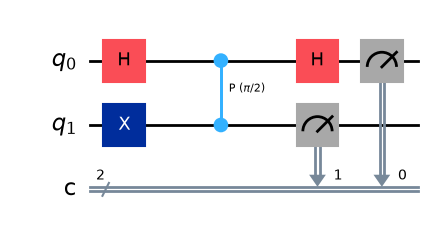

(1) Tras X(q1): psi


<IPython.core.display.Latex object>

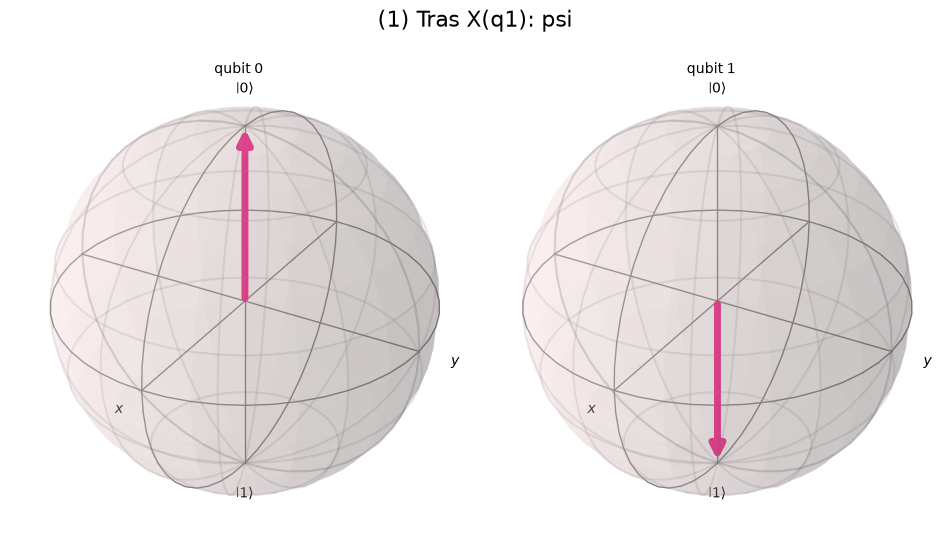

(2) Tras H(q0): psi'


<IPython.core.display.Latex object>

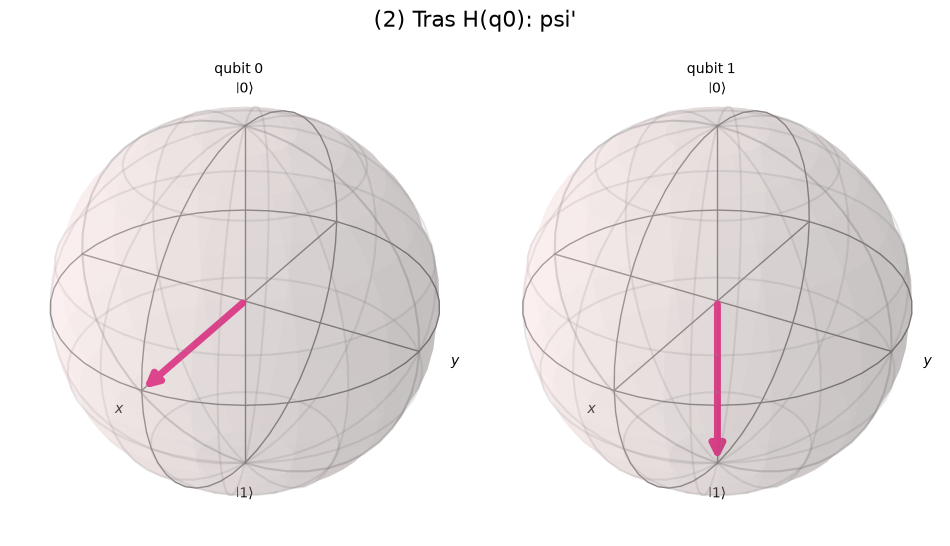

(3) Tras CP(θ): psi''


<IPython.core.display.Latex object>

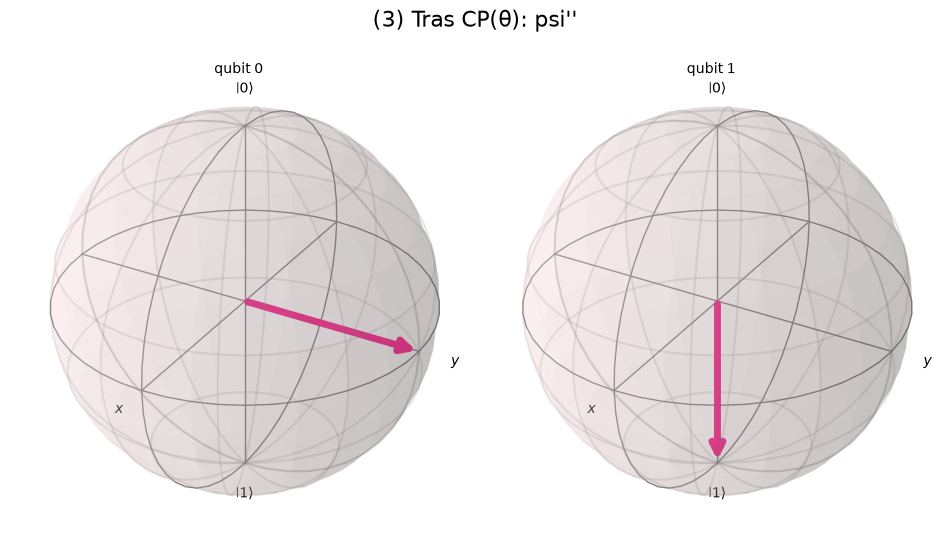

(4) Tras H(q0): psi'''


<IPython.core.display.Latex object>

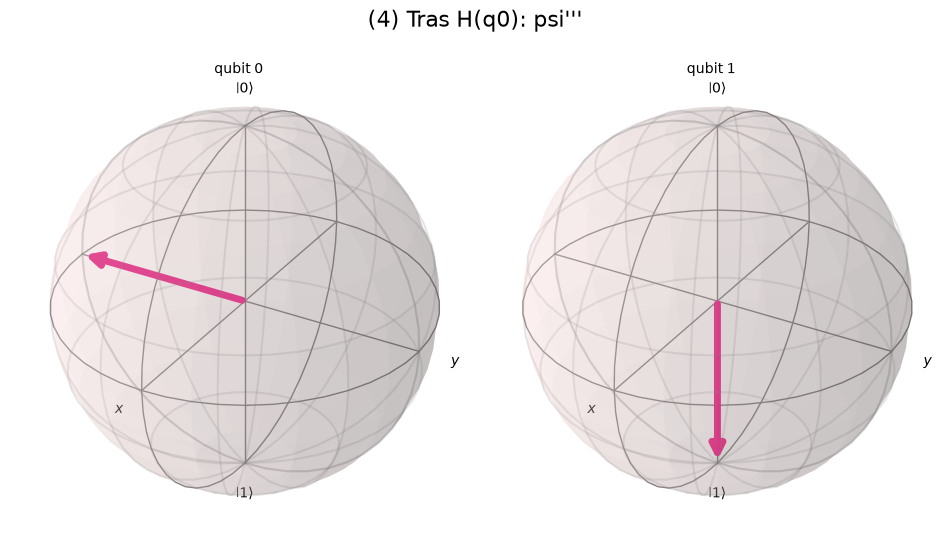

| Punto                  | Bloch q0 (x, y, z)       | Bloch q1 (x, y, z)       |
|------------------------|--------------------------|--------------------------|
| (1) Tras X(q1): psi    | (+0.000, +0.000, +1.000) | (+0.000, +0.000, -1.000) |
| (2) Tras H(q0): psi'   | (+1.000, +0.000, +0.000) | (+0.000, +0.000, -1.000) |
| (3) Tras CP(θ): psi''  | (+0.000, +1.000, +0.000) | (+0.000, +0.000, -1.000) |
| (4) Tras H(q0): psi''' | (+0.000, -1.000, +0.000) | (+0.000, +0.000, -1.000) |


In [33]:
def pasos_cp(theta):
    return [('(1) Tras X(q1): psi', lambda qc: qc.x(1)),
            ("(2) Tras H(q0): psi'", lambda qc: qc.h(0)),
            ("(3) Tras CP(θ): psi''", lambda qc: qc.cp(theta, 0, 1)),
            ("(4) Tras H(q0): psi'''", lambda qc: qc.h(0))]

def circuito_cp_medido(qc_sin_medidas):
    qc = QuantumCircuit(2, 2)
    qc.compose(qc_sin_medidas, inplace=True)
    qc.measure([0, 1], [0, 1])
    return qc

qc_23, est_23 = evolucion(2, pasos_cp(np.pi / 2))
qc_23_med = circuito_cp_medido(qc_23)
display(qc_23_med.draw('mpl'))
mostrar_evolucion(est_23[1:], bloch=True)
tabla_bloch(est_23[1:], [0, 1])

**Probabilidades de medir 0 y 1 en $q_0$**, teoría frente a simulación:

|           |   A mano |   Statevector |   Aer (4096 disparos) |
|-----------|----------|---------------|-----------------------|
| P(q0 = 0) |   0.5000 |        0.5000 |                0.4990 |
| P(q0 = 1) |   0.5000 |        0.5000 |                0.5010 |


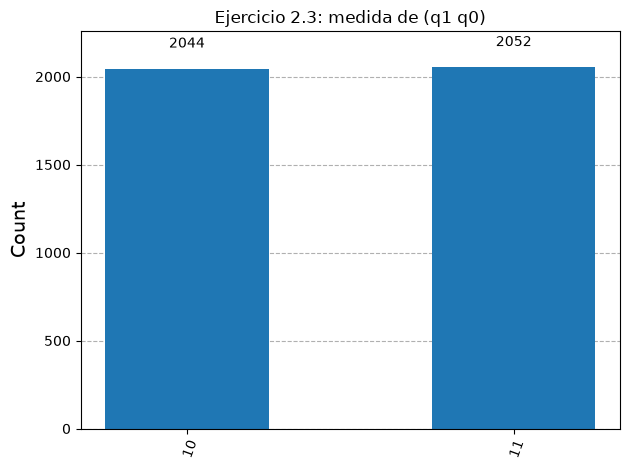

In [34]:
psi_fin = est_23[-1][1]
p_teo = psi_fin.probabilities([0])                 # [P(q0=0), P(q0=1)]
counts_23 = simular(qc_23_med)
p1_sim = prob_q0_uno(counts_23)
print(tabulate([['P(q0 = 0)', 0.5, p_teo[0], 1 - p1_sim],
                ['P(q0 = 1)', 0.5, p_teo[1], p1_sim]],
               headers=['', 'A mano', 'Statevector', 'Aer (4096 disparos)'], floatfmt='.4f', tablefmt='github'))
display(plot_histogram(counts_23, title='Ejercicio 2.3: medida de (q1 q0)'))

### **Ejercicio 2.4. Generalización a $CP(\theta)$**

**a) Barrido $\theta=k\pi/4$, $k=1,\dots,7$.** Como $CP(\theta)$ con $q_1=|1\rangle$ aplica $|1\rangle\to e^{i\theta}|1\rangle$ solo si el control vale 1, tras la $CP$ (punto 3) $q_0=\tfrac{1}{\sqrt2}(|0\rangle+e^{i\theta}|1\rangle)$, es decir, vector de Bloch $(\cos\theta,\sin\theta,0)$: $q_0$ **recorre el ecuador** girando $\theta$ alrededor de $z$. La $H$ final (punto 4) es una rotación de $\pi$ alrededor del eje $(x+z)/\sqrt2$, que lleva $(x,y,z)\to(z,-y,x)$, así que $q_0$ pasa a $(0,-\sin\theta,\cos\theta)$, es decir, **recorre el meridiano $yz$**.

**b)** $P(q_0=1)=\tfrac{1-z}{2}=\tfrac{1-\cos\theta}{2}=\sin^2(\theta/2)$.

In [35]:
ks = np.arange(1, 8)
filas_24, bloch3, bloch4, p1_sim_24 = [], [], [], []
for k in ks:
    theta = k * np.pi / 4
    qc_, est_ = evolucion(2, pasos_cp(theta))
    v3, v4 = vector_bloch(est_[3][1], 0), vector_bloch(est_[4][1], 0)
    bloch3.append(v3); bloch4.append(v4)
    p1 = prob_q0_uno(simular(circuito_cp_medido(qc_)))
    p1_sim_24.append(p1)
    ok3 = np.allclose(v3, (np.cos(theta), np.sin(theta), 0))
    ok4 = np.allclose(v4, (0, -np.sin(theta), np.cos(theta)))
    filas_24.append([f'{k}π/4', f'({v3[0]:+.3f}, {v3[1]:+.3f}, {v3[2]:+.3f})', f'({v4[0]:+.3f}, {v4[1]:+.3f}, {v4[2]:+.3f})',
                     'OK' if (ok3 and ok4) else 'ERROR', np.sin(theta / 2) ** 2, p1])
print(tabulate(filas_24, headers=['θ', 'Bloch q0 punto 3', 'Bloch q0 punto 4', 'Teoría', 'P1 teórica', 'P1 simulada'],
               floatfmt='.4f', tablefmt='github'))

| θ    | Bloch q0 punto 3         | Bloch q0 punto 4         | Teoría   |   P1 teórica |   P1 simulada |
|------|--------------------------|--------------------------|----------|--------------|---------------|
| 1π/4 | (+0.707, +0.707, +0.000) | (-0.000, -0.707, +0.707) | OK       |       0.1464 |        0.1511 |
| 2π/4 | (+0.000, +1.000, +0.000) | (+0.000, -1.000, +0.000) | OK       |       0.5000 |        0.5010 |
| 3π/4 | (-0.707, +0.707, +0.000) | (+0.000, -0.707, -0.707) | OK       |       0.8536 |        0.8540 |
| 4π/4 | (-1.000, +0.000, +0.000) | (-0.000, -0.000, -1.000) | OK       |       1.0000 |        1.0000 |
| 5π/4 | (-0.707, -0.707, -0.000) | (-0.000, +0.707, -0.707) | OK       |       0.8536 |        0.8540 |
| 6π/4 | (-0.000, -1.000, +0.000) | (+0.000, +1.000, -0.000) | OK       |       0.5000 |        0.5010 |
| 7π/4 | (+0.707, -0.707, -0.000) | (-0.000, +0.707, +0.707) | OK       |       0.1464 |        0.1511 |


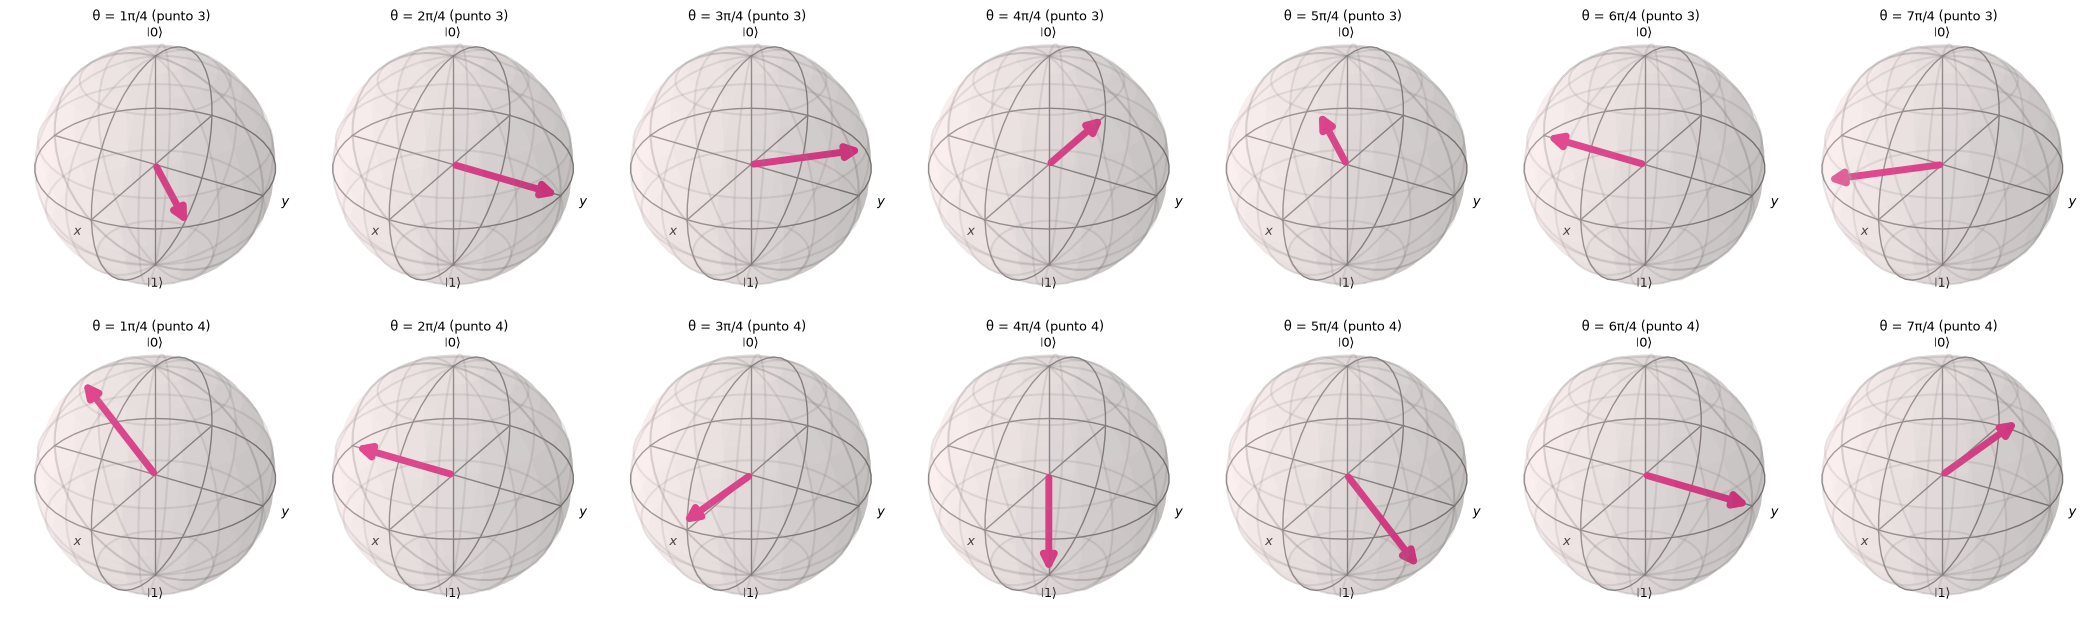

In [36]:
fig = plt.figure(figsize=(21, 6.5))
for j, k in enumerate(ks):
    for fila, (vs, nombre) in enumerate([(bloch3, 'punto 3'), (bloch4, 'punto 4')]):
        ax = fig.add_subplot(2, 7, fila * 7 + j + 1, projection='3d')
        plot_bloch_vector(list(vs[j]), ax=ax, title=f'θ = {k}π/4 ({nombre})', font_size=9)
plt.tight_layout()
display(fig)
plt.close(fig)

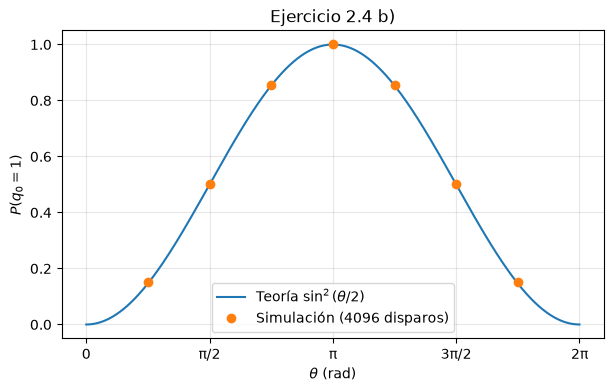

Máxima desviación simulación - teoría: 0.0047 (compatible con el ruido estadístico ~ 1/sqrt(4096) = 0.0156 )


In [37]:
theta_ax = np.linspace(0, 2 * np.pi, 400)
plt.figure(figsize=(7, 4))
plt.plot(theta_ax, np.sin(theta_ax / 2) ** 2, label=r'Teoría $\sin^2(\theta/2)$')
plt.plot(ks * np.pi / 4, p1_sim_24, 'o', label='Simulación (4096 disparos)')
plt.xlabel(r'$\theta$ (rad)'); plt.ylabel(r'$P(q_0=1)$')
plt.xticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi], ['0', 'π/2', 'π', '3π/2', '2π'])
plt.grid(alpha=0.3); plt.legend(); plt.title('Ejercicio 2.4 b)')
plt.show()
print('Máxima desviación simulación - teoría:', np.max(np.abs(np.array(p1_sim_24) - np.sin(ks * np.pi / 8) ** 2)).round(4),
      '(compatible con el ruido estadístico ~ 1/sqrt(4096) =', round(1 / np.sqrt(shots), 4), ')')

**c) Encadenar dos $CP(\pi/2)$.** $CP(\theta)=\mathrm{diag}(1,1,1,e^{i\theta})$ es diagonal, así que su potencia $k$-ésima se obtiene elevando cada elemento: $CP(\theta)^k=\mathrm{diag}(1,1,1,e^{ik\theta})=CP(k\theta)$. En QPE esto permite implementar $U^{2^j}$ como $j$ aplicaciones repetidas (o, para la puerta de fase, directamente con un solo $CP(2^j\theta)$).

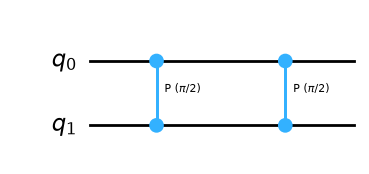

Operator(CP(π/2) · CP(π/2)) == Operator(CP(π)): True
CP(θ)^k = CP(kθ) para 8 valores de θ y k = 1..8: True


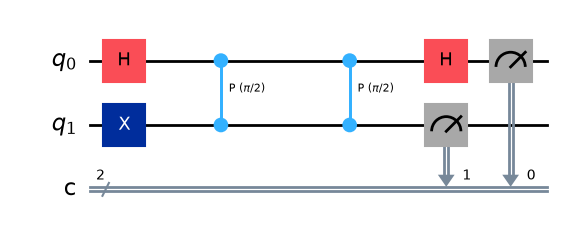

P(q0=1) con dos CP(π/2): 1.0 (teoría sin^2(π/2) = 1)


In [38]:
# Dos CP(pi/2) encadenadas frente a una CP(pi)
doble = QuantumCircuit(2); doble.cp(np.pi / 2, 0, 1); doble.cp(np.pi / 2, 0, 1)
unica = QuantumCircuit(2); unica.cp(np.pi, 0, 1)
display(doble.draw('mpl'))
print('Operator(CP(π/2) · CP(π/2)) == Operator(CP(π)):', Operator(doble).equiv(Operator(unica)))

# Comprobación general CP(θ)^k = CP(kθ)
ok = all(np.allclose(np.linalg.matrix_power(Operator(CPhaseGate(th)).data, kk), Operator(CPhaseGate(kk * th)).data)
         for th in np.linspace(0.1, 3, 8) for kk in range(1, 9))
print('CP(θ)^k = CP(kθ) para 8 valores de θ y k = 1..8:', ok)

# Efecto en el circuito del ejercicio 2.3: P(q0=1) con theta = pi
qc_c = QuantumCircuit(2, 2); qc_c.x(1); qc_c.h(0)
qc_c.cp(np.pi / 2, 0, 1); qc_c.cp(np.pi / 2, 0, 1)
qc_c.h(0); qc_c.measure([0, 1], [0, 1])
display(qc_c.draw('mpl'))
print('P(q0=1) con dos CP(π/2):', prob_q0_uno(simular(qc_c)), '(teoría sin^2(π/2) = 1)')

### **Ejercicio 2.5. Oráculo booleano frente a oráculo de fase**

Con un qubit de datos $x\equiv q_0$ y la ancilla $y\equiv q_1$, el oráculo de $f(x)=x$ es un CNOT (dato $\to$ ancilla): $U_f|x\rangle|y\rangle=|x\rangle|y\oplus x\rangle$.

**Predicción.** a) Con $|y\rangle=|0\rangle$ se obtiene $|x\rangle|f(x)\rangle$ y con $|y\rangle=|1\rangle$ se obtiene $|x\rangle|\overline{f(x)}\rangle$. b) $|x\rangle|+\rangle$ es autovector con $\lambda=1$ (porque $X|+\rangle=|+\rangle$) y $|x\rangle|-\rangle$ con $\lambda=(-1)^{f(x)}$ (porque $X|-\rangle=-|-\rangle$). Simulador: `AerSimulator` para la tabla de verdad (es una medida) y `Statevector` para los productos escalares $\lambda=\langle\psi_{in}|\psi_{out}\rangle$ (que requieren amplitudes).

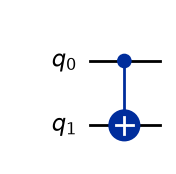

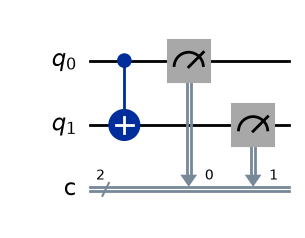

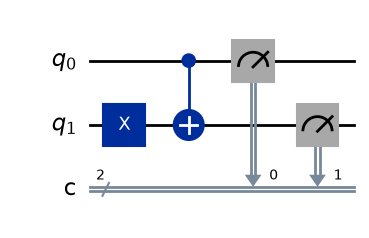

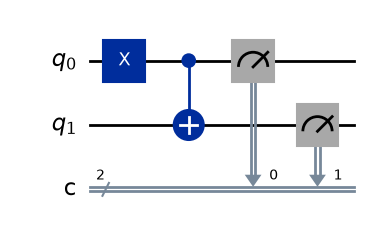

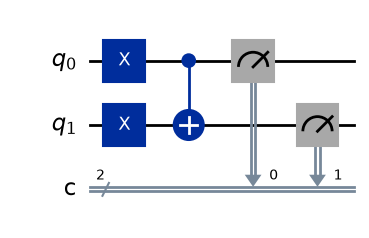

|   x |   y | Teórico (x, y⊕f(x))   | Simulado   | Estado   |   Probabilidad |
|-----|-----|-----------------------|------------|----------|----------------|
|   0 |   0 | |0>|0>                | |0>|0>     | OK       |              1 |
|   0 |   1 | |0>|1>                | |0>|1>     | OK       |              1 |
|   1 |   0 | |1>|1>                | |1>|1>     | OK       |              1 |
|   1 |   1 | |1>|0>                | |1>|0>     | OK       |              1 |


In [39]:
uf_25 = QuantumCircuit(2, name='U_f')      # q0 = x (dato), q1 = y (ancilla)
uf_25.cx(0, 1)
display(uf_25.draw('mpl'))

filas_25a = []
for x in (0, 1):
    for y in (0, 1):
        qc_ = QuantumCircuit(2, 2)
        if x: qc_.x(0)
        if y: qc_.x(1)
        qc_.compose(uf_25, inplace=True)
        qc_.measure([0, 1], [0, 1])
        display(qc_.draw('mpl'))
        counts_ = simular(qc_)
        clave = max(counts_, key=counts_.get)                  # 'y_out x_out'
        y_out, x_out = int(clave[0]), int(clave[1])
        filas_25a.append([x, y, f'|{x}>|{y ^ x}>', f'|{x_out}>|{y_out}>', 'OK' if (x_out, y_out) == (x, y ^ x) else 'ERROR',
                          counts_[clave] / shots])
print(tabulate(filas_25a, headers=['x', 'y', 'Teórico (x, y⊕f(x))', 'Simulado', 'Estado', 'Probabilidad'], tablefmt='github'))

**b) Autovectores.** Se prepara $|x\rangle|a\rangle$ con $a\in\{+,-\}$, se aplica $U_f$ y se calcula $\lambda=\langle\psi_{in}|\psi_{out}\rangle$; $|\psi_{in}\rangle$ es autovector si $|\psi_{out}\rangle=\lambda|\psi_{in}\rangle$.

In [40]:
filas_25b = []
for x in (0, 1):
    for a in ('+', '-'):
        psi_in = Statevector.from_label(a + str(x))          # etiqueta = 'q1 q0' = 'ancilla dato'
        psi_out = psi_in.evolve(uf_25)
        lam = psi_in.inner(psi_out)                          # <psi_in|psi_out>
        es_autovector = np.allclose(psi_out.data, lam * psi_in.data)
        lam_teo = 1 if a == '+' else (-1) ** x
        filas_25b.append([f'|{x}>|{a}>', f'{lam.real:+.3f}{lam.imag:+.3f}j', lam_teo, es_autovector,
                          'OK' if (es_autovector and np.isclose(lam, lam_teo)) else 'ERROR'])
print(tabulate(filas_25b, headers=['Estado de entrada', 'λ = <in|out>', 'λ teórico', '¿Autovector?', 'Estado'], tablefmt='github'))

# Retroceso de fase: con el dato en |+> y la ancilla en |->, U_f lleva el dato a |->
psi_in = Statevector.from_label('-+')
psi_out = psi_in.evolve(uf_25)
print('\nU_f |+>|->  ==  |->|->  :', psi_out.equiv(Statevector.from_label('--')))

| Estado de entrada   | λ = <in|out>   |   λ teórico | ¿Autovector?   | Estado   |
|---------------------|----------------|-------------|----------------|----------|
| |0>|+>              | +1.000+0.000j  |           1 | True           | OK       |
| |0>|->              | +1.000+0.000j  |           1 | True           | OK       |
| |1>|+>              | +1.000+0.000j  |           1 | True           | OK       |
| |1>|->              | -1.000+0.000j  |          -1 | True           | OK       |

U_f |+>|->  ==  |->|->  : True


## **Bloque 3. Algoritmos de consulta: Deutsch, Deutsch-Jozsa y Bernstein-Vazirani**

### **Ejercicio 3.1: Algoritmo de Deutsch**

In [41]:
def oraculo(qc, tipo):
    if tipo == "a":          # f(x) = 0 -> identidad
        pass
    elif tipo == "b":        # f(x) = 1 -> X sobre la ancilla
        qc.x(1)
    elif tipo == "c":        # f(x) = x -> CNOT
        qc.cx(0, 1)
    elif tipo == "d":        # f(x) = NOT x -> CNOT + X
        qc.cx(0, 1)
        qc.x(1)

def deutsch(tipo):
    qc = QuantumCircuit(2, 1)
    qc.x(1)                  # ancilla en |1>
    qc.h([0, 1])
    qc.barrier()
    oraculo(qc, tipo)
    qc.barrier()
    qc.h(0)
    qc.measure(0, 0)
    return qc

deutsch_qcs = {}
for t in "abcd":
    qc = deutsch(t)
    deutsch_qcs[t] = qc

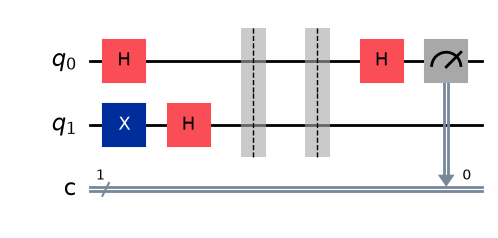

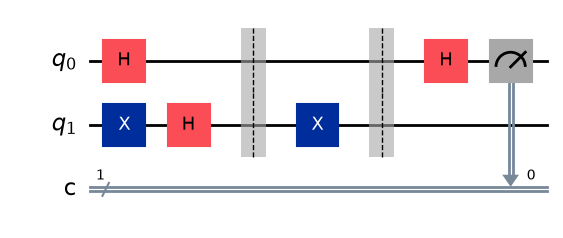

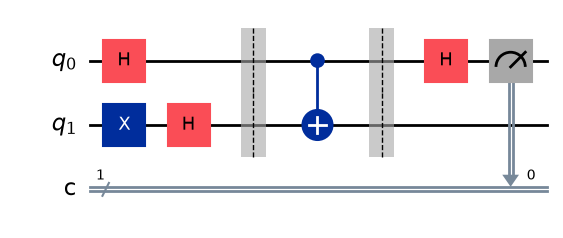

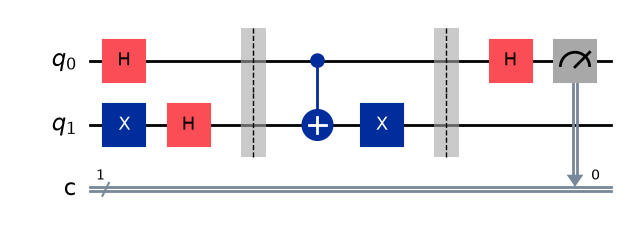

In [42]:
for qc in deutsch_qcs.values():
    display(qc.draw('mpl'))

**Simulación**

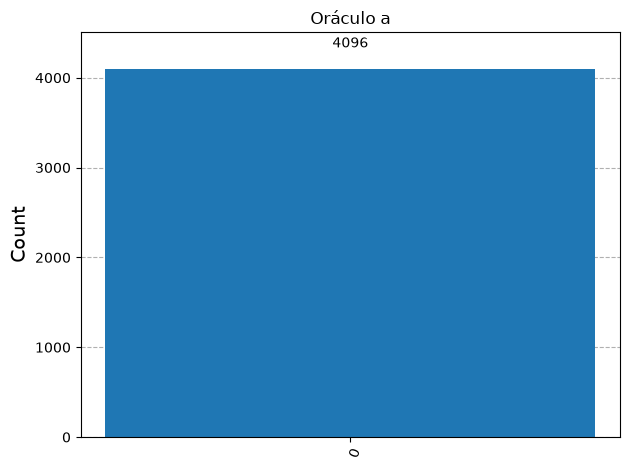

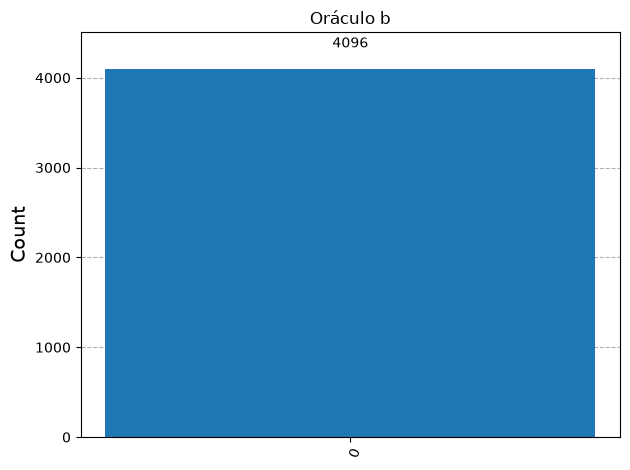

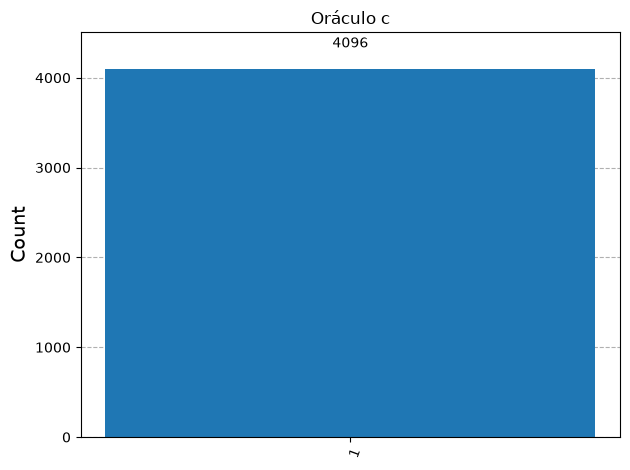

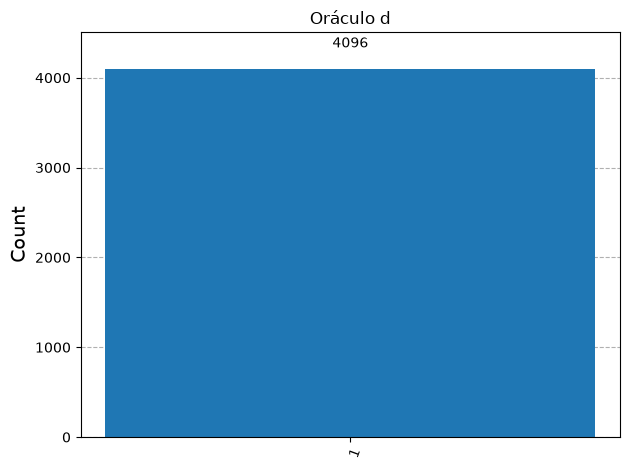

In [43]:
for nombre, qc in deutsch_qcs.items():
    counts = sim.run(transpile(qc, sim), shots=shots).result().get_counts()
    fig = plot_histogram(counts, title=f"Oráculo {nombre}")
    display(fig)

### **Ejercicio 3.2: Deutsch-Jozsa con $n=2$**

In [44]:
def oraculos3_2(tipo):
    qc = QuantumCircuit(3, name = f'oraculo {tipo}')
    if tipo == "a":
        pass
    elif tipo == "b":
        qc.cx(0, 2)
        qc.cx(1, 2)
    else: #apartado c)
        qc.ccx(0, 1, 2)
    display(qc.draw('mpl'))
    return qc.to_gate()

def deutsch_jozsa(oraculo, n = 2):
    qc = QuantumCircuit(n + 1, n)
    qc.x(n)
    qc.h(range(n + 1))
    
    qc.append(oraculo, range(n + 1))
    qc.h(range(n + 1))
    qc.measure(range(n), range(n))
    return qc


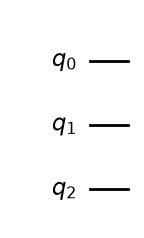

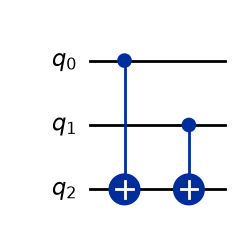

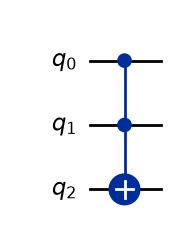

In [45]:
djcircuits = {}
for t in "abc":
    qc = deutsch_jozsa(oraculos3_2(t), 2)
    djcircuits[t] = qc
    qc.draw('mpl')

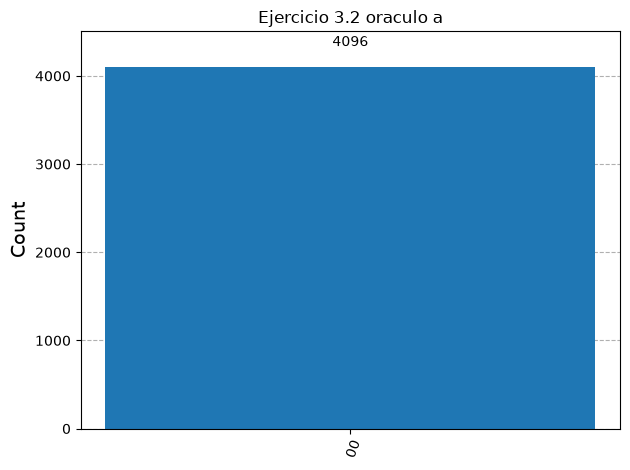

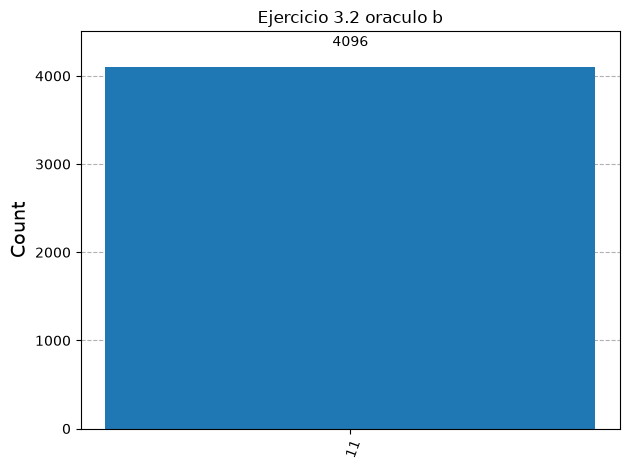

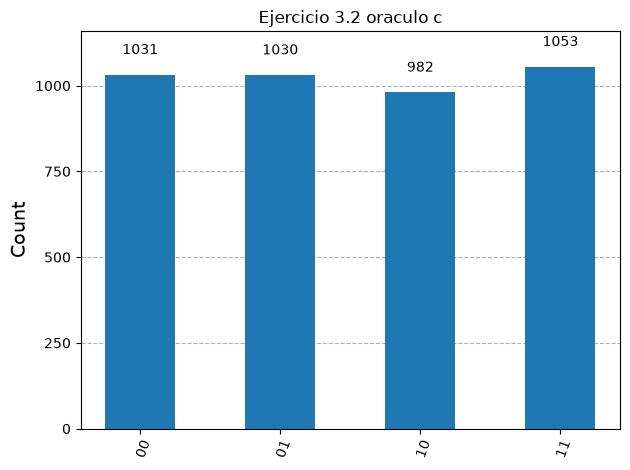

In [46]:
for nombre, qc in djcircuits.items():
    counts = sim.run(transpile(qc, sim), shots=shots).result().get_counts()
    fig = plot_histogram(counts, title=f"Ejercicio 3.2 oraculo {nombre}")
    display(fig)

### **Ejercicio 3.3: Bernstein-Vazirani**

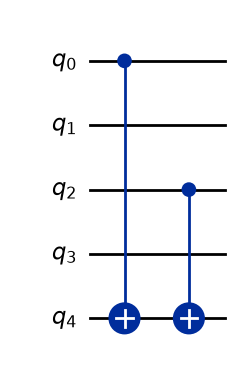

In [47]:
#Construyo oraculo para clave oculta a = 1010
oraculo_a1 = QuantumCircuit(5, name = "oraculo_a1")
oraculo_a1.cx(0, 4)
oraculo_a1.cx(2, 4)
display(oraculo_a1.draw('mpl'))
oraculoa1_gate = oraculo_a1.to_gate()

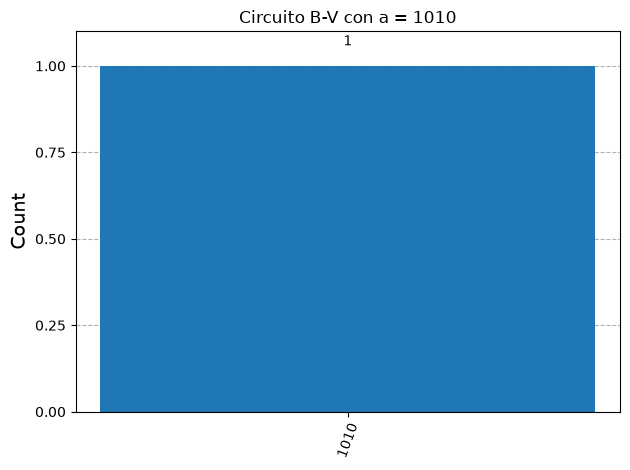

In [48]:
bvazirani_a1 = QuantumCircuit(5, 4, name = "circuito_bernstein_vazirani")
bvazirani_a1.x(4)
bvazirani_a1.h(range(5))
bvazirani_a1.barrier()
bvazirani_a1.append(oraculoa1_gate, range(5))
bvazirani_a1.barrier()
bvazirani_a1.h(range(5))
bvazirani_a1.measure(range(4), range(3, -1, -1)) #Invierto los bits de medida

counts = sim.run(transpile(bvazirani_a1, sim), shots=1).result().get_counts()
fig = plot_histogram(counts, title=f"Circuito B-V con a = 1010")
display(fig)

**Probar otra clave $a = 1101$**

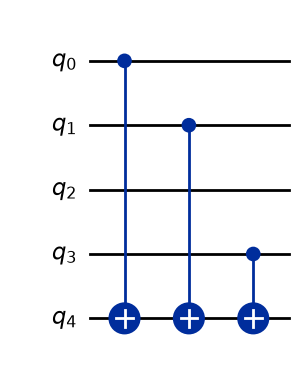

In [49]:
#Construyo oraculo para clave oculta a = 1101
oraculo_a2 = QuantumCircuit(5, name = "oraculo_a2")
oraculo_a2.cx(0, 4)
oraculo_a2.cx(1, 4)
oraculo_a2.cx(3, 4)
display(oraculo_a2.draw('mpl'))

oraculoa2_gate = oraculo_a2.to_gate()

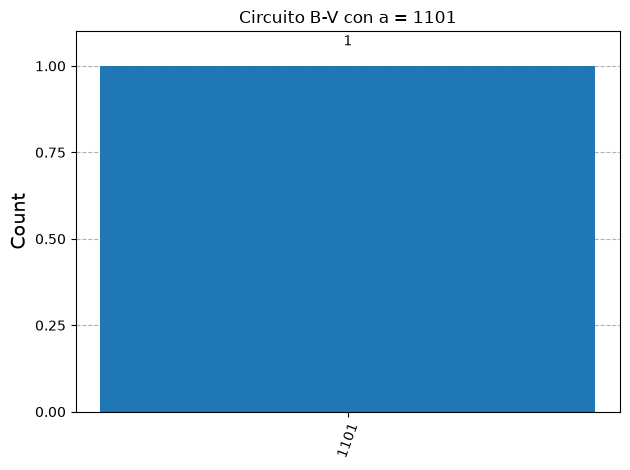

In [50]:
bvazirani_a2 = QuantumCircuit(5, 4, name = "circuito_bernstein_vazirani_a2")
bvazirani_a2.x(4)
bvazirani_a2.h(range(5))
bvazirani_a2.barrier()
bvazirani_a2.append(oraculoa2_gate, range(5))
bvazirani_a2.barrier()
bvazirani_a2.h(range(5))
bvazirani_a2.measure(range(4), range(3, -1, -1)) #Invierto los bits de medida

counts = sim.run(transpile(bvazirani_a2, sim), shots=1).result().get_counts()
fig = plot_histogram(counts, title=f"Circuito B-V con a = 1101")
display(fig)

### **Ejercicio E1: Deutsch-Jozsa con un oraculo dado**

**Implementación del circuito y simulacion**

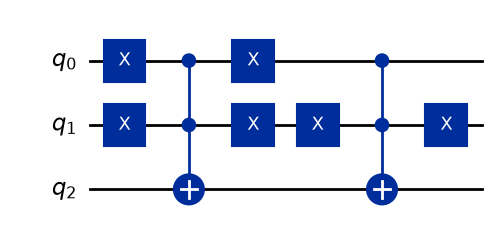

In [51]:
# Construyo el oraculo
dj_f = QuantumCircuit(3, name = "DJ_F")
dj_f.x([0, 1])
dj_f.ccx(0, 1, 2)
dj_f.x([0, 1])

dj_f.x(1)
dj_f.ccx(0, 1, 2)
dj_f.x(1)
display(dj_f.draw('mpl'))

oraculo_djf = dj_f.to_gate()

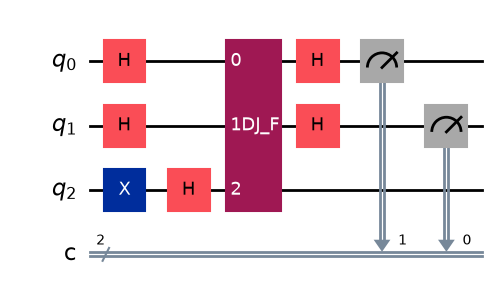

In [52]:
# Implemento el circuito
e1dj = QuantumCircuit(3, 2)
e1dj.x(2)
e1dj.h([0, 1, 2])
e1dj.append(oraculo_djf, [0, 1, 2])
e1dj.h([0, 1])

e1dj.measure([0, 1], [1, 0])
e1dj.draw('mpl')

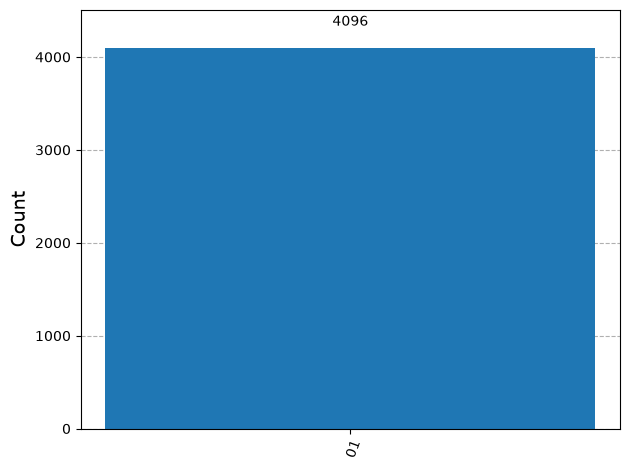

In [53]:
counts = sim.run(transpile(e1dj, sim), shots = shots).result().get_counts()
plot_histogram(counts)

**Determinar la función $f: \{0, 1\}² \rightarrow \{0, 1\}$**

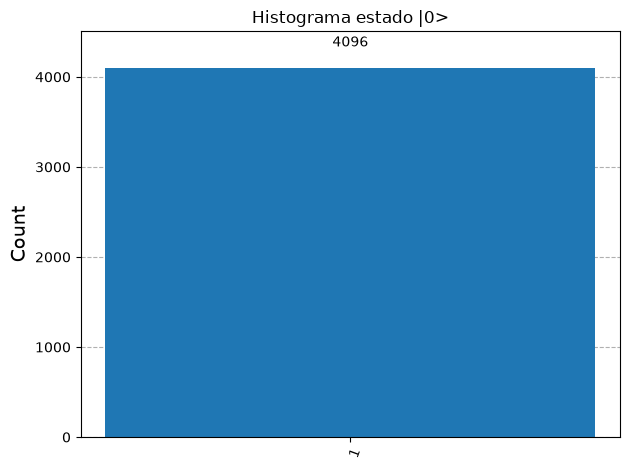

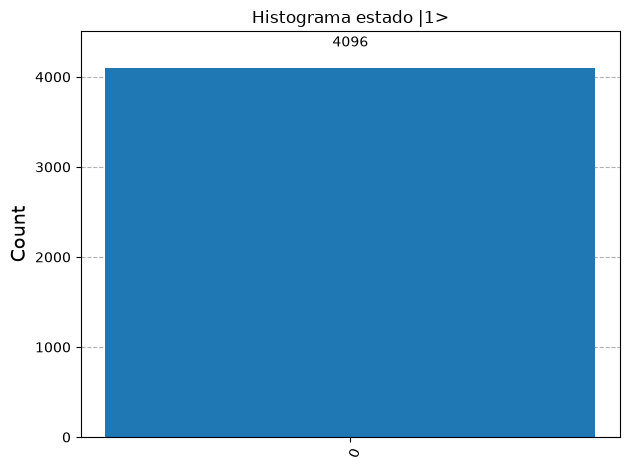

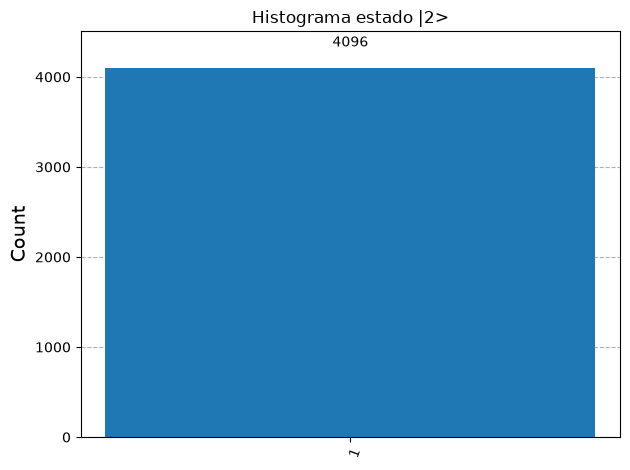

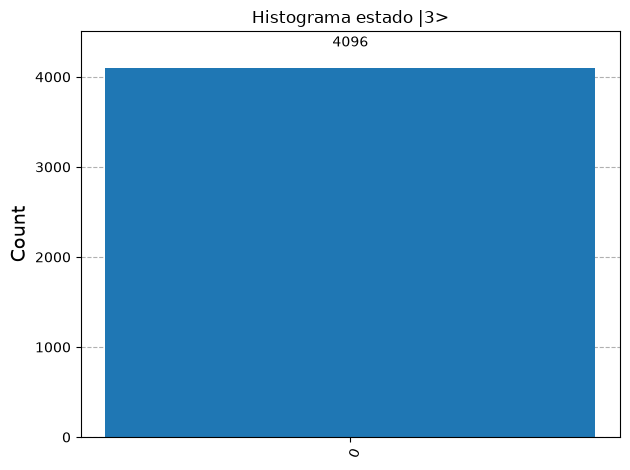

In [54]:
def init_circuit (qc, valor):
    if valor == 0:
        pass
    elif valor == 1:
        qc.x(1)
    elif valor == 2:
        qc.x(0)
    else:
        qc.x([0, 1])

for i in range(4):
    qc = QuantumCircuit(3, 1)
    init_circuit(qc, i)
    qc.append(oraculo_djf, [0, 1, 2])
    qc.measure(2, 0)
    #print(qc)

    counts = sim.run(transpile(qc, sim), shots = shots).result().get_counts()
    display(plot_histogram(counts, title = f'Histograma estado |{i}>'))

## **Bloque 4. Algoritmo de Grover**

In [55]:
# Convenio: w = 'x_{n-1}...x_0' con x_j en el qubit q_j (Qiskit, little-endian).
# El estado |w> es el índice int(w, 2) del vector de estado.
def z_multicontrolada(qc, n):
    """Z con n-1 controles sobre q_{n-1}: H · MCX · H. Cambia el signo solo de |1...1>."""
    if n == 1:
        qc.z(0)
    else:
        qc.h(n - 1)
        qc.mcx(list(range(n - 1)), n - 1)
        qc.h(n - 1)

def oraculo_fase(w):
    """O|x> = -|x> si x = w, |x> en otro caso. Se rodean con X los qubits en los que w tiene un 0."""
    n = len(w)
    qc = QuantumCircuit(n, name=f'O_{w}')
    ceros = [j for j, b in enumerate(w[::-1]) if b == '0']
    if ceros: qc.x(ceros)
    z_multicontrolada(qc, n)
    if ceros: qc.x(ceros)
    return qc

def difusion(n):
    """D = 2|s><s| - I = H^n (2|0><0| - I) H^n.
    X^n · MCZ · X^n = I - 2|0><0|, así que H^n X^n MCZ X^n H^n = -D; la fase global pi lo convierte exactamente en D."""
    qc = QuantumCircuit(n, name='D')
    qc.h(range(n)); qc.x(range(n))
    z_multicontrolada(qc, n)
    qc.x(range(n)); qc.h(range(n))
    qc.global_phase = np.pi
    return qc

def grover(w, k, medir=True):
    """H^n, k iteraciones G = D·O y (opcional) medida de los n qubits."""
    n = len(w)
    qc = QuantumCircuit(n, n) if medir else QuantumCircuit(n)
    qc.h(range(n))
    O, D = oraculo_fase(w).to_gate(), difusion(n).to_gate()
    for _ in range(k):
        qc.barrier()
        qc.append(O, range(n))
        qc.append(D, range(n))
    if medir:
        qc.barrier()
        qc.measure(range(n), range(n))
    return qc

def p_teorica(k, N, M=1):
    """P_k(w) = sen^2((2k+1) theta), sen theta = sqrt(M/N)."""
    theta = np.arcsin(np.sqrt(M / N))
    return np.sin((2 * k + 1) * theta) ** 2

### **Ejercicio 4.1. Aplicación del operador de difusión**

O|s> = |a> : True
media = 0.26517 = 3/(4√8) = 0.26517
b_i (i≠3) = 1/(2√8) = 0.17678 | b_3 = 5/(2√8) = 0.88388


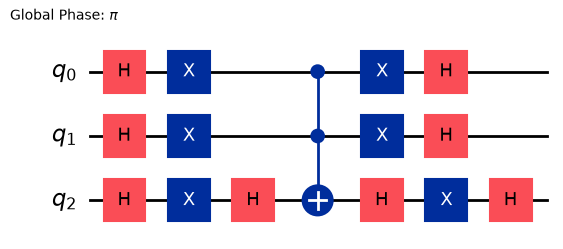

Operator(D) = 2|s><s| - I : True
|b> circuito = |b> a mano : True
|   i |   |i> |      a_i |   b_i (a mano) |   b_i (circuito) |
|-----|-------|----------|----------------|------------------|
|   0 |   000 |  0.35355 |        0.17678 |          0.17678 |
|   1 |   001 |  0.35355 |        0.17678 |          0.17678 |
|   2 |   010 |  0.35355 |        0.17678 |          0.17678 |
|   3 |   011 | -0.35355 |        0.88388 |          0.88388 |
|   4 |   100 |  0.35355 |        0.17678 |          0.17678 |
|   5 |   101 |  0.35355 |        0.17678 |          0.17678 |
|   6 |   110 |  0.35355 |        0.17678 |          0.17678 |
|   7 |   111 |  0.35355 |        0.17678 |          0.17678 |

P(w) antes = 0.1250  ->  después = 0.78125 = 25/32 = 0.78125


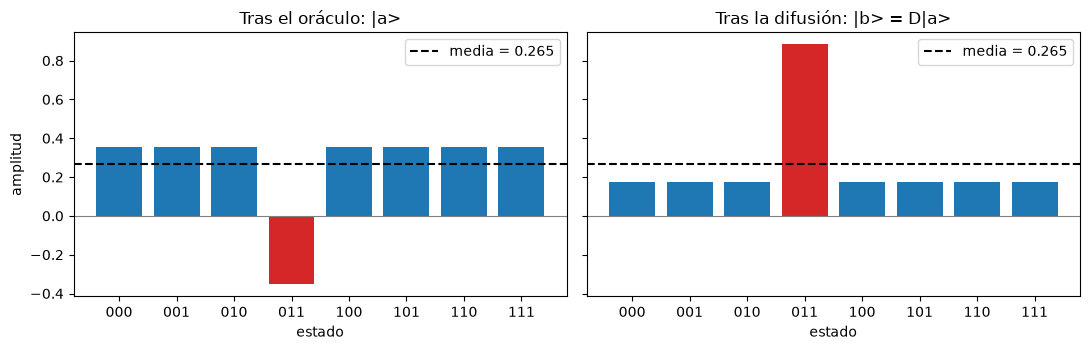

In [56]:
n, N, w = 3, 8, '011'
idx_w = int(w, 2)

# Estado |a>: a_i = 1/sqrt(8) salvo a_3 = -1/sqrt(8)
a = np.ones(N) / np.sqrt(N)
a[idx_w] *= -1

# (1) El oráculo aplicado a |s> produce exactamente |a>
h3 = QuantumCircuit(n); h3.h(range(n))
a_circ = Statevector(h3).evolve(oraculo_fase(w))
print('O|s> = |a> :', np.allclose(a_circ.data, a))

# (2) A mano: inversión respecto a la media  b_i = 2·media - a_i
media = a.mean()                                  # (7 - 1)/(8·sqrt(8)) = 3/(4·sqrt(8))
b_mano = 2 * media - a
print(f'media = {media:.5f} = 3/(4√8) = {3 / (4 * np.sqrt(8)):.5f}')
print(f'b_i (i≠3) = 1/(2√8) = {1 / (2 * np.sqrt(8)):.5f} | b_3 = 5/(2√8) = {5 / (2 * np.sqrt(8)):.5f}')

# (3) Con el circuito de D
display(difusion(n).draw('mpl'))
b_circ = Statevector(a).evolve(difusion(n))
print('Operator(D) = 2|s><s| - I :', np.allclose(Operator(difusion(n)).data,
      2 * np.outer(np.ones(N) / np.sqrt(N), np.ones(N) / np.sqrt(N)) - np.eye(N)))
print('|b> circuito = |b> a mano :', np.allclose(b_circ.data, b_mano))
print(tabulate([[i, format(i, '03b'), a[i], b_mano[i], b_circ.data[i].real] for i in range(N)],
               headers=['i', '|i>', 'a_i', 'b_i (a mano)', 'b_i (circuito)'], floatfmt='.5f', tablefmt='github'))
print(f'\nP(w) antes = {a[idx_w]**2:.4f}  ->  después = {b_mano[idx_w]**2:.5f} = 25/32 = {25/32:.5f}')

# (4) Gráfica de la inversión respecto a la media
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for axx, v, t in zip(ax, (a, b_mano), ('Tras el oráculo: |a>', 'Tras la difusión: |b> = D|a>')):
    axx.bar(range(N), v, color=['tab:red' if i == idx_w else 'tab:blue' for i in range(N)])
    axx.axhline(v.mean(), color='k', ls='--', label=f'media = {v.mean():.3f}')
    axx.axhline(0, color='gray', lw=0.8)
    axx.set_xticks(range(N)); axx.set_xticklabels([format(i, '03b') for i in range(N)])
    axx.set_xlabel('estado'); axx.set_title(t); axx.legend()
ax[0].set_ylabel('amplitud')
plt.tight_layout(); plt.show()

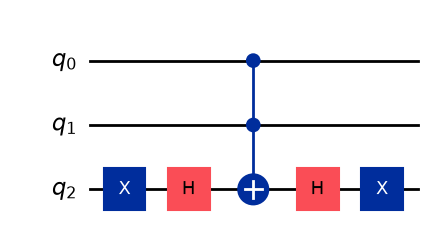

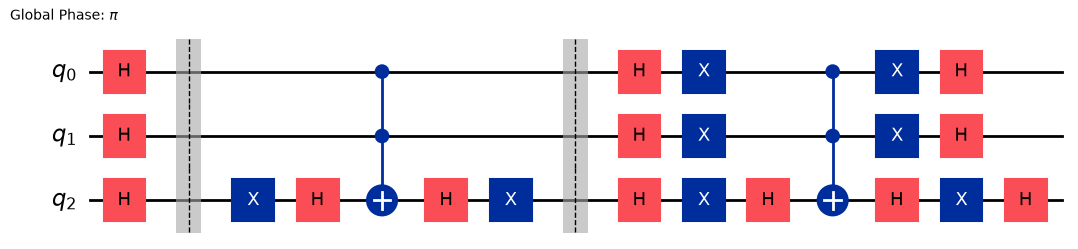

|b> del circuito completo = |b> a mano : True


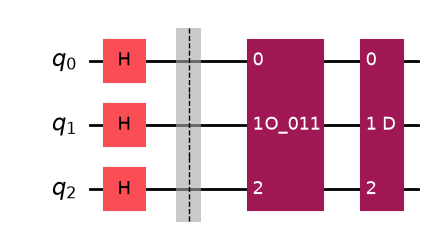

In [57]:
# (0) Oráculo O_w que marca |011>, descompuesto en X, H y MCX
display(oraculo_fase(w).draw('mpl'))

# (0b) Circuito completo de una iteración: H^n -> O -> D (sin medidas)
qc_41 = QuantumCircuit(n)
qc_41.h(range(n))                                  # |s> = H^n |0...0>
qc_41.barrier()
qc_41.compose(oraculo_fase(w), inplace=True)       # O_w   -> |a>
qc_41.barrier()
qc_41.compose(difusion(n), inplace=True)           # D     -> |b>
display(qc_41.draw('mpl'))

print('|b> del circuito completo = |b> a mano :',
      np.allclose(Statevector(qc_41).data, b_mano))     # b_mano se define en (2)

# Versión compacta, con O y D como cajas (más legible para la memoria)
qc_cajas = QuantumCircuit(n)
qc_cajas.h(range(n)); qc_cajas.barrier()
qc_cajas.append(oraculo_fase(w).to_gate(), range(n))
qc_cajas.append(difusion(n).to_gate(), range(n))
display(qc_cajas.draw('mpl'))

### **Ejercicio 4.2. Número de iteraciones**

theta = arcsen(1/√8) = 0.36137 rad = 20.70°


|   k |   (2k+1)θ (rad) |   P_k teórica |   P_k Statevector |   P_k simulada |
|-----|-----------------|---------------|-------------------|----------------|
|   0 |          0.3614 |        0.1250 |            0.1250 |         0.1313 |
|   1 |          1.0841 |        0.7813 |            0.7812 |         0.7795 |
|   2 |          1.8068 |        0.9453 |            0.9453 |         0.9475 |
|   3 |          2.5296 |        0.3301 |            0.3301 |         0.3318 |
|   4 |          3.2523 |        0.0122 |            0.0122 |         0.0115 |

Mínimo k con P_k >= 90 %: k = 2  (P = 0.9453);  (π/4)√N = 2.221


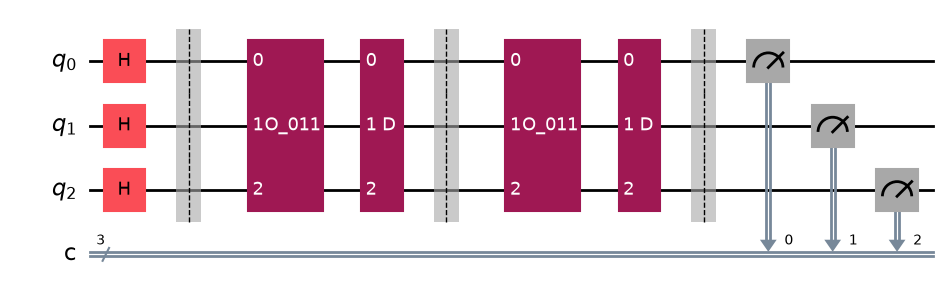

|   Estado |   P teórica |   P simulada |   Conteo teórico |   Conteo simulado |
|----------|-------------|--------------|------------------|-------------------|
|      000 |      0.0078 |       0.0066 |               32 |                27 |
|      001 |      0.0078 |       0.0081 |               32 |                33 |
|      010 |      0.0078 |       0.0073 |               32 |                30 |
|      011 |      0.9453 |       0.9475 |             3872 |              3881 |
|      100 |      0.0078 |       0.0071 |               32 |                29 |
|      101 |      0.0078 |       0.0100 |               32 |                41 |
|      110 |      0.0078 |       0.0066 |               32 |                27 |
|      111 |      0.0078 |       0.0068 |               32 |                28 |

Test chi^2 frente a la predicción: p-valor = 0.654 (compatible al 5 %)


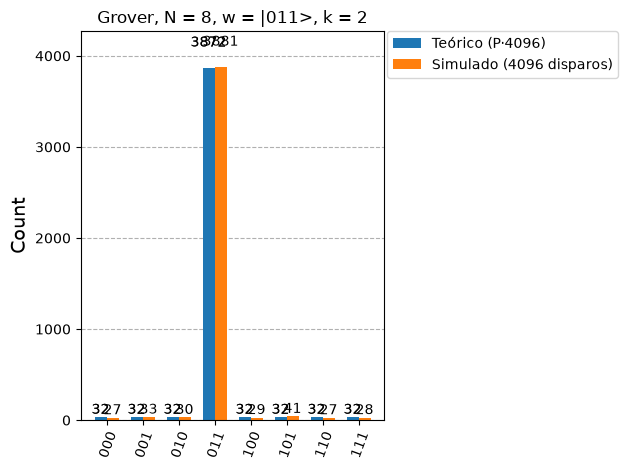

In [58]:
n, N, w = 3, 8, '011'
theta = np.arcsin(1 / np.sqrt(N))
print(f'theta = arcsen(1/√8) = {theta:.5f} rad = {np.degrees(theta):.2f}°')

filas = []
for k in range(5):
    sv = Statevector(grover(w, k, medir=False))
    c = simular(grover(w, k))
    filas.append([k, f'{(2 * k + 1) * theta:.4f}', p_teorica(k, N), sv.probabilities_dict().get(w, 0), c.get(w, 0) / shots])
print(tabulate(filas, headers=['k', '(2k+1)θ (rad)', 'P_k teórica', 'P_k Statevector', 'P_k simulada'], floatfmt='.4f', tablefmt='github'))

k_min = next(k for k in range(50) if p_teorica(k, N) >= 0.90)
print(f'\nMínimo k con P_k >= 90 %: k = {k_min}  (P = {p_teorica(k_min, N):.4f});  (π/4)√N = {np.pi / 4 * np.sqrt(N):.3f}')

# Algoritmo completo con k_min iteraciones
qc_g = grover(w, k_min)
display(qc_g.draw('mpl'))
counts_g = simular(qc_g)

# Predicción: P_k en |w> y (1-P_k)/(N-1) en cada uno de los demás estados (en número de disparos)
P = p_teorica(k_min, N)
claves = [format(i, f'0{n}b') for i in range(N)]
probs_teo = {c: (P if c == w else (1 - P) / (N - 1)) for c in claves}
esperados = {c: int(round(p * shots)) for c, p in probs_teo.items()}
print(tabulate([[c, probs_teo[c], counts_g.get(c, 0) / shots, esperados[c], counts_g.get(c, 0)] for c in claves],
               headers=['Estado', 'P teórica', 'P simulada', 'Conteo teórico', 'Conteo simulado'], floatfmt='.4f', tablefmt='github'))
p_chi = chisquare([counts_g.get(c, 0) for c in claves], [probs_teo[c] * shots for c in claves]).pvalue
print(f'\nTest chi^2 frente a la predicción: p-valor = {p_chi:.3f} ({"compatible" if p_chi > 0.05 else "NO compatible"} al 5 %)')
display(plot_histogram([esperados, dict(counts_g)], legend=[f'Teórico (P·{shots})', f'Simulado ({shots} disparos)'],
                       title=f'Grover, N = 8, w = |{w}>, k = {k_min}'))

### **Ejercicio 4.3. Límite de probabilidad**

|   k |   (2k+1)θ |   P_k teórica |   P_k simulada |
|-----|-----------|---------------|----------------|
|   0 |    0.3614 |        0.1250 |         0.1313 |
|   1 |    1.0841 |        0.7813 |         0.7795 |
|   2 |    1.8068 |        0.9453 |         0.9475 |
|   3 |    2.5296 |        0.3301 |         0.3318 |
|   4 |    3.2523 |        0.0122 |         0.0115 |
|   5 |    3.9750 |        0.5480 |         0.5483 |
|   6 |    4.6978 |        0.9998 |         0.9993 |
|   7 |    5.4205 |        0.5770 |         0.5784 |
|   8 |    6.1432 |        0.0195 |         0.0171 |
|   9 |    6.8660 |        0.3029 |         0.3022 |
|  10 |    7.5887 |        0.9313 |         0.9343 |
|  11 |    8.3114 |        0.8049 |         0.8035 |
|  12 |    9.0342 |        0.1450 |         0.1475 |
|  13 |    9.7569 |        0.1063 |         0.1057 |
|  14 |   10.4796 |        0.7566 |         0.7568 |
|  15 |   11.2024 |        0.9578 |         0.9583 |

(2k+1)θ = π/2 -> k = 1.673: no es entero. Mej

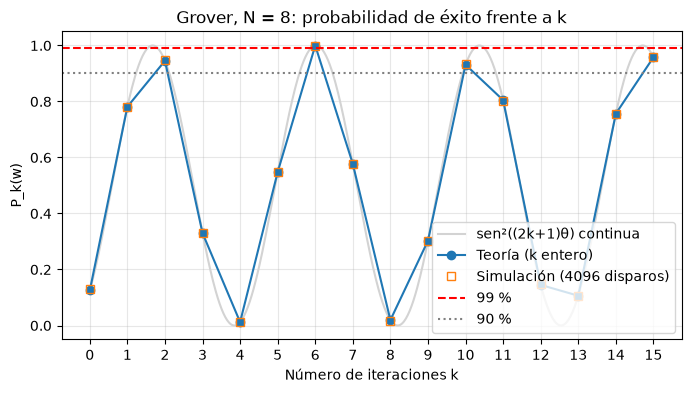

In [59]:
n, N, w = 3, 8, '011'
theta = np.arcsin(1 / np.sqrt(N))
ks = np.arange(0, 16)
P_teo = p_teorica(ks, N)
P_sim = [simular(grover(w, int(k))).get(w, 0) / shots for k in ks]

print(tabulate([[int(k), f'{(2 * k + 1) * theta:.4f}', pt, ps] for k, pt, ps in zip(ks, P_teo, P_sim)],
               headers=['k', '(2k+1)θ', 'P_k teórica', 'P_k simulada'], floatfmt='.4f', tablefmt='github'))

k_cont = (np.pi / (2 * theta) - 1) / 2            # k continuo donde (2k+1)θ = π/2
print(f'\n(2k+1)θ = π/2 -> k = {k_cont:.3f}: no es entero. Mejor entero en la 1ª subida: k = {int(np.argmax(P_teo[:4]))} con P = {P_teo[:4].max():.4f}')
k99 = next(int(k) for k, p in zip(ks, P_teo) if p >= 0.99)
print(f'Primer k con P_k >= 99 %: k = {k99}  (P = {p_teorica(k99, N):.5f}; (2k+1)θ = {(2 * k99 + 1) * theta:.4f} vs 3π/2 = {1.5 * np.pi:.4f})')
print(f'Periodo de P_k en k: π/(2θ) = {np.pi / (2 * theta):.3f} (no entero)')

plt.figure(figsize=(8, 4))
kk = np.linspace(0, 15, 600)
plt.plot(kk, p_teorica(kk, N), color='lightgray', label='sen²((2k+1)θ) continua')
plt.plot(ks, P_teo, 'o-', label='Teoría (k entero)')
plt.plot(ks, P_sim, 's', mfc='none', label=f'Simulación ({shots} disparos)')
plt.axhline(0.99, color='r', ls='--', label='99 %'); plt.axhline(0.90, color='gray', ls=':', label='90 %')
plt.xlabel('Número de iteraciones k'); plt.ylabel('P_k(w)'); plt.xticks(ks)
plt.grid(alpha=0.3); plt.legend(loc='lower right'); plt.title('Grover, N = 8: probabilidad de éxito frente a k')
plt.show()

## **Bloque 5. Estimación cuántica de fase (QPE)**

### **Ejercicio 5.1. Fase exacta: puerta S**

In [60]:
# En esta sección se usara el PhaseGate() de Qiskit
u = PhaseGate(np.pi/2) # Theta = 1/4
t = 2

In [61]:
def qpe_circuit(t, gate: Gate):
    cgate = gate.control(1)
    qc = QuantumCircuit(t + 1, t,  name = f'Circuito QPE')
    qc.h(range(t))
    qc.x(t)
    for i in range(t - 1, -1, -1):
        times = 2**i
        for _ in range(times):
            qc.append(cgate, [i, t])
    qc.append(QFTGate(t).inverse(), range(t))
    qc.measure(range(t), range(t))
    return qc

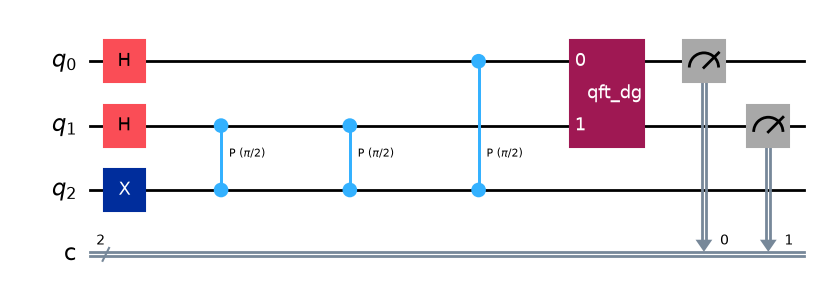

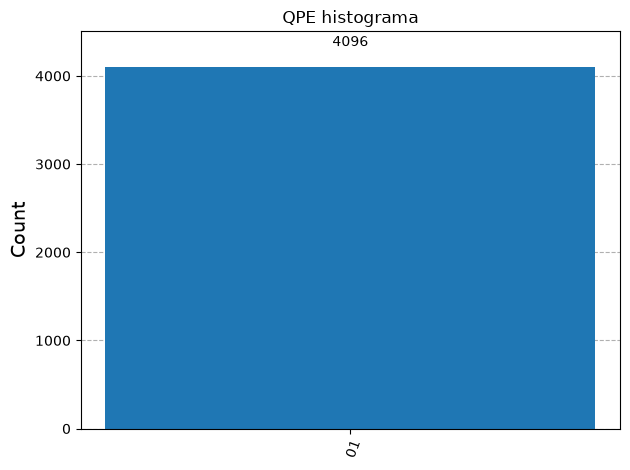

In [62]:
qc = qpe_circuit(t, u)
display(qc.draw('mpl'))
counts = sim.run(transpile(qc, sim), shots = shots).result().get_counts()
plot_histogram(counts, title = fr'QPE histograma')

### **Ejercicio 5.2. Fase no exacta con pocos qubits**

In [63]:
t = 2
u1 = PhaseGate(4*np.pi/5)
u2 = PhaseGate(6*np.pi/32)

In [64]:
def get_probs(counts, shots):
    probs = {}
    for k, v in counts.items():
        probs[k] = v/shots

    return probs

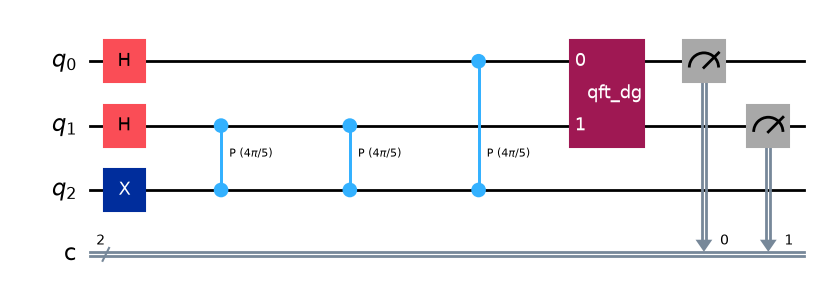

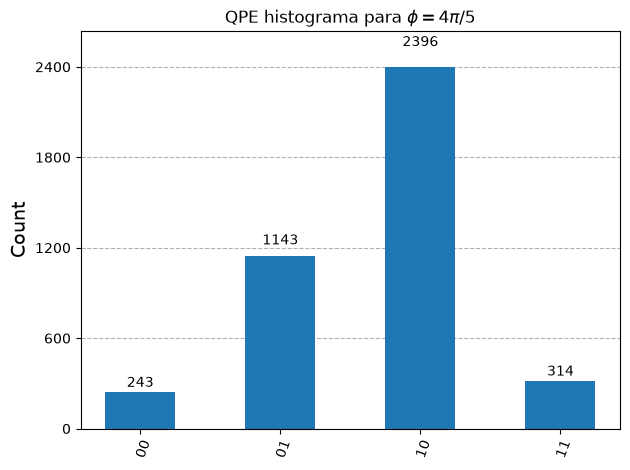

In [65]:
qc = qpe_circuit(t, u1)
display(qc.draw('mpl'))
counts = sim.run(transpile(qc, sim), shots = shots).result().get_counts()
plot_histogram(counts, title = fr'QPE histograma para $\phi = 4\pi/5$')

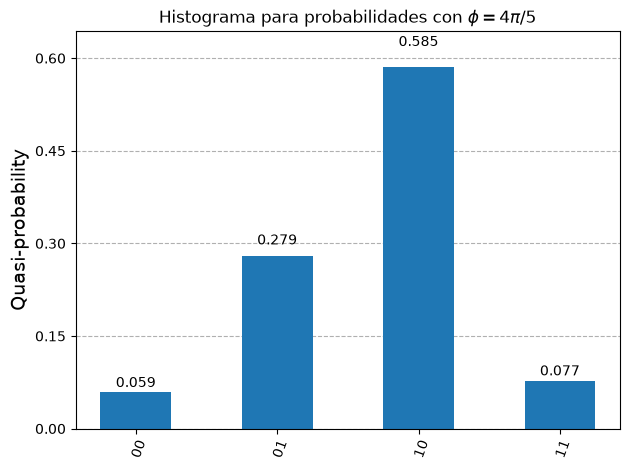

In [66]:
cprobs = get_probs(counts, shots)
plot_histogram(cprobs, title = fr'Histograma para probabilidades con $\phi = 4\pi/5$')

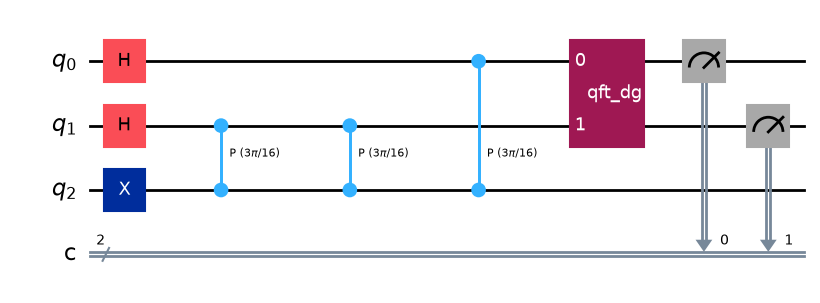

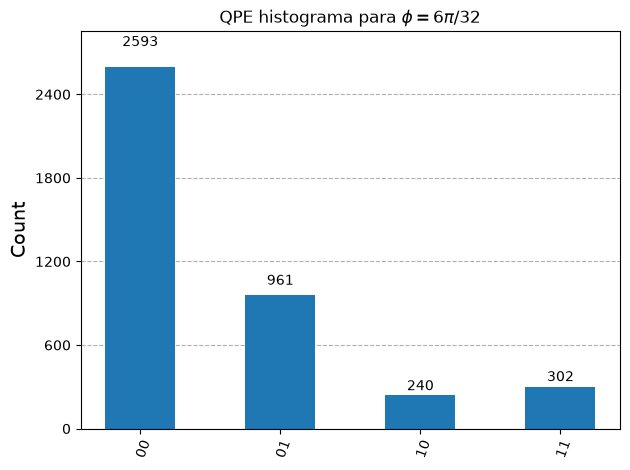

In [67]:
qc = qpe_circuit(t, u2)
display(qc.draw('mpl'))
counts = sim.run(transpile(qc, sim), shots = shots).result().get_counts()
plot_histogram(counts, title = fr'QPE histograma para $\phi = 6\pi/32$')

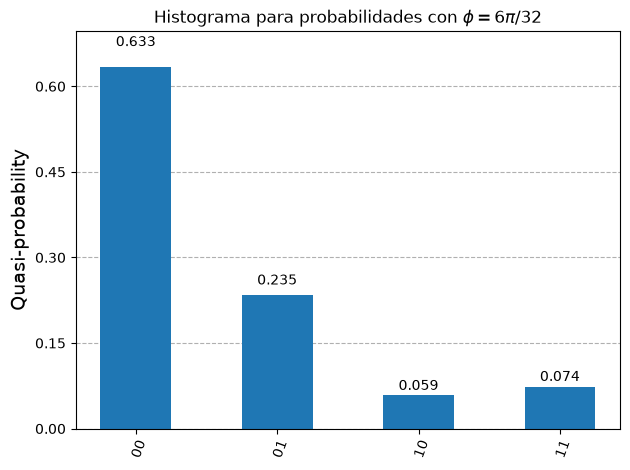

In [68]:
cprobs = get_probs(counts, shots)
plot_histogram(cprobs, title = fr'Histograma para probabilidades con $\phi = 6\pi/32$')

### **Ejercicio 5.3. Aumento del número de qubits de conteo**

In [69]:
t = 5

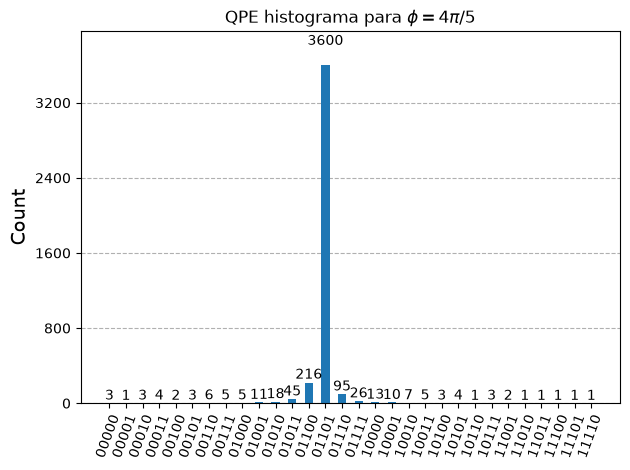

In [70]:
qc = qpe_circuit(t, u1)
counts = sim.run(transpile(qc, sim), shots = shots).result().get_counts()
plot_histogram(counts, title = fr'QPE histograma para $\phi = 4\pi/5$')

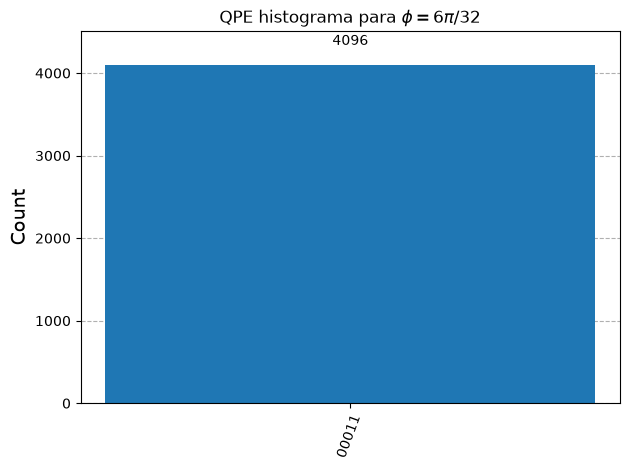

In [71]:
qc = qpe_circuit(t, u2)
counts = sim.run(transpile(qc, sim), shots = shots).result().get_counts()
plot_histogram(counts, title = fr'QPE histograma para $\phi = 6\pi/32$')

### **Ejercicio E2.1. QPE con $t = 3$ para $U = P(2\pi/3)$**

In [72]:
t = 3
u = PhaseGate(2*np.pi/3)

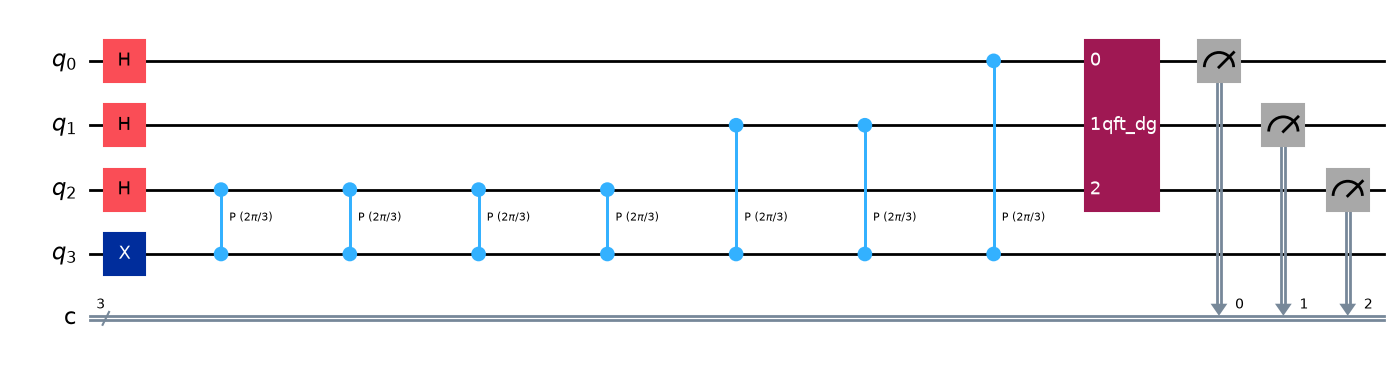

In [73]:
#Apartados a), b)
cu = u.control(1)
qc = QuantumCircuit(t + 1, t, name = f'Circuito QPE')
qc.x(t) # Preparo el estado |1> que es un autovector

qc.h(range(t))
point1 = Statevector(qc)

for i in range(t - 1, -1, -1):
    times = 2**i
    for _ in range(times):
        qc.append(cu, [i, t])
point2 = Statevector(qc)

qc.append(QFTGate(t).inverse(), range(t))
point3 = Statevector(qc)
qc.measure(range(t), range(t))
display(qc.draw('mpl'))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

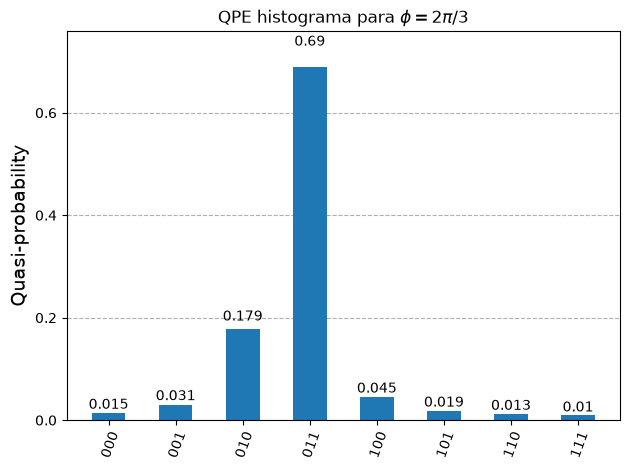

In [74]:
display(point1.draw("latex"))
display(point2.draw("latex"))
display(point3.draw("latex"))

counts = sim.run(transpile(qc, sim), shots = shots).result().get_counts()
plot_histogram(get_probs(counts, shots), title = fr'QPE histograma para $\phi = 2\pi/3$')

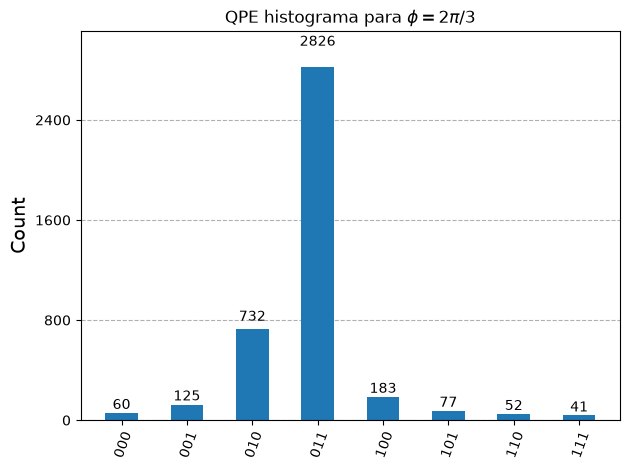

In [75]:
plot_histogram(counts, title = fr'QPE histograma para $\phi = 2\pi/3$')

### **Ejercicio E2.2. Mejora de la precisión**

In [76]:
ts = [i for i in range(4, 16)]
u = PhaseGate(2*np.pi/3)
cu = u.control(1)
theta = 1/3

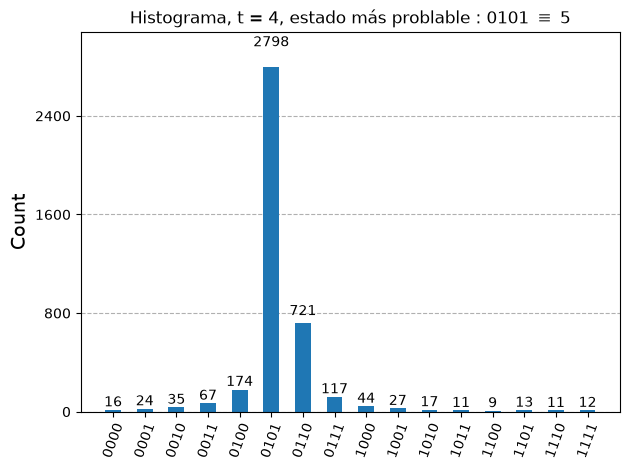

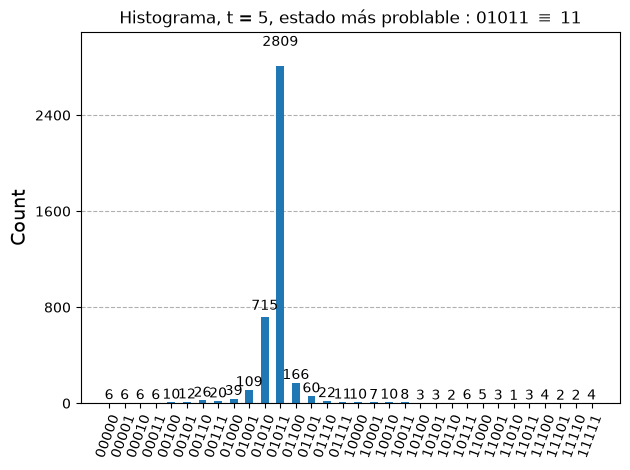

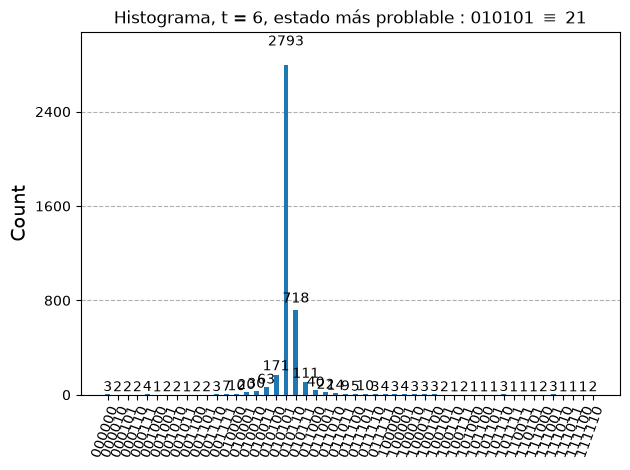

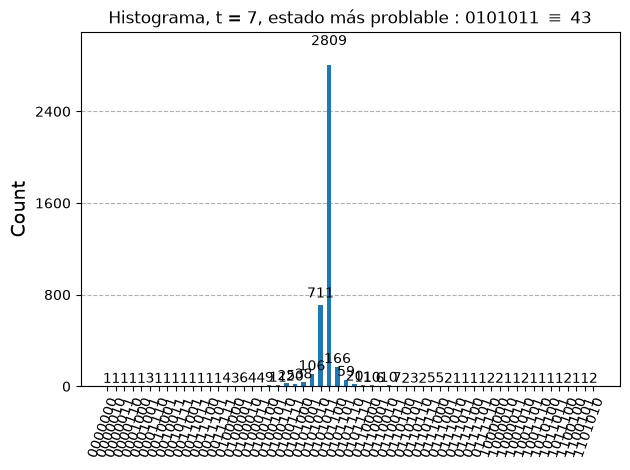

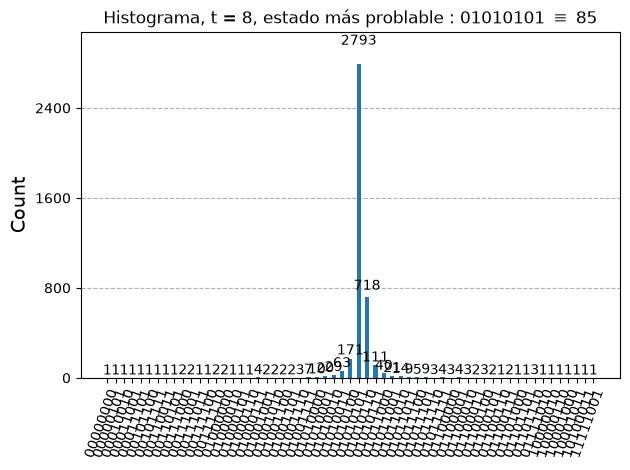

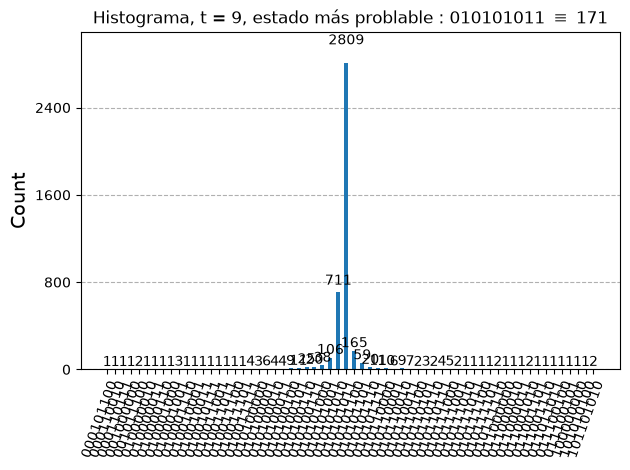

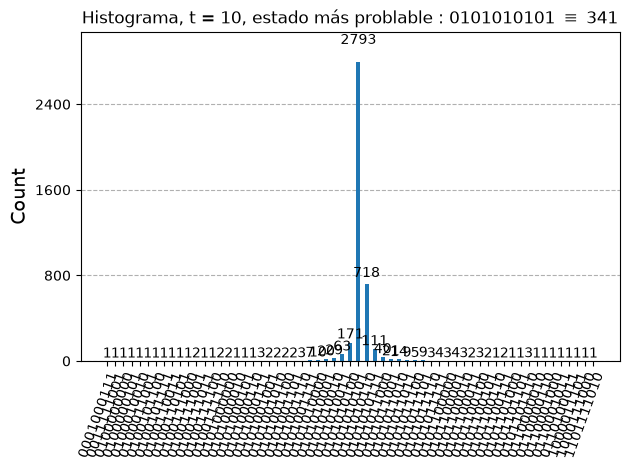

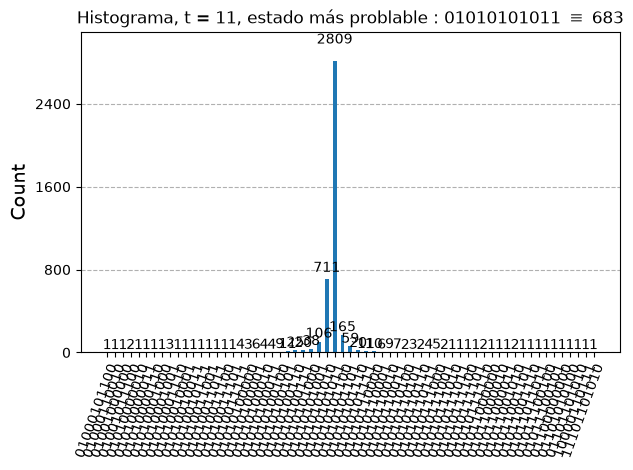

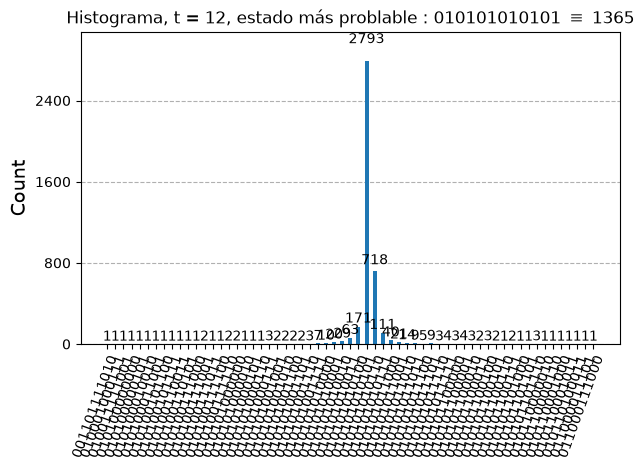

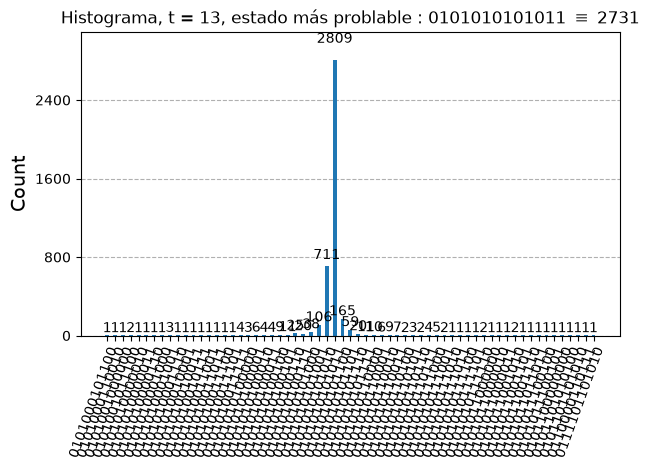

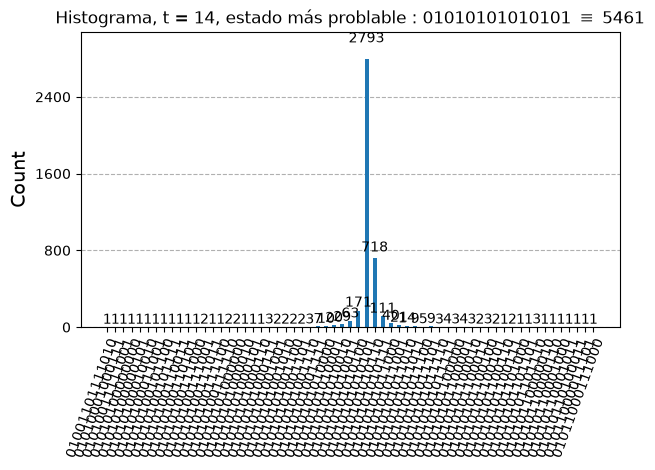

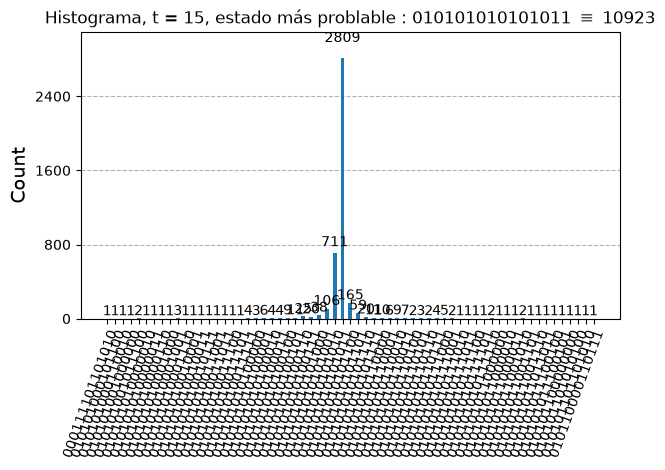

In [77]:
maxm = {}
thetas = {}
probs = {}
abs_errors= {}
for t in ts: 
    qc = qpe_circuit(t, u)
    counts = sim.run(transpile(qc, sim), shots = shots).result().get_counts()
    m = max(counts, key = counts.get)
    maxm[t] = m
    thetas[t] = int(m, 2)/(2**t)
    abs_errors[t] = abs(theta - int(m, 2)/(2**t)) 
    probs[t] = counts[m]/shots
    display(plot_histogram(counts, title = fr'Histograma, t = {t}, estado más problable : {m} $\equiv$ {int(m, 2)}'))

In [78]:
print(maxm)
print(probs)
print(thetas)
print(abs_errors)

{4: '0101', 5: '01011', 6: '010101', 7: '0101011', 8: '01010101', 9: '010101011', 10: '0101010101', 11: '01010101011', 12: '010101010101', 13: '0101010101011', 14: '01010101010101', 15: '010101010101011'}
{4: 0.68310546875, 5: 0.685791015625, 6: 0.681884765625, 7: 0.685791015625, 8: 0.681884765625, 9: 0.685791015625, 10: 0.681884765625, 11: 0.685791015625, 12: 0.681884765625, 13: 0.685791015625, 14: 0.681884765625, 15: 0.685791015625}
{4: 0.3125, 5: 0.34375, 6: 0.328125, 7: 0.3359375, 8: 0.33203125, 9: 0.333984375, 10: 0.3330078125, 11: 0.33349609375, 12: 0.333251953125, 13: 0.3333740234375, 14: 0.33331298828125, 15: 0.333343505859375}
{4: 0.020833333333333315, 5: 0.010416666666666685, 6: 0.005208333333333315, 7: 0.002604166666666685, 8: 0.0013020833333333148, 9: 0.0006510416666666852, 10: 0.00032552083333331483, 11: 0.00016276041666668517, 12: 8.138020833331483e-05, 13: 4.069010416668517e-05, 14: 2.034505208331483e-05, 15: 1.017252604168517e-05}


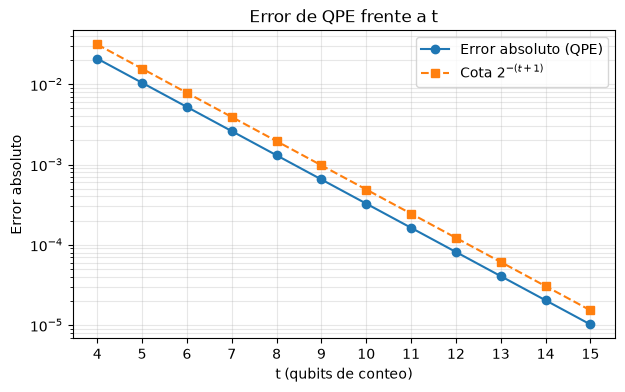

True


In [79]:
ts = sorted(abs_errors)                          # errores = {t: error_abs}
err = [abs_errors[t] for t in ts]
cota = [2**-(t + 1) for t in ts]

plt.figure(figsize=(7, 4))
plt.semilogy(ts, err, "o-", label="Error absoluto (QPE)")
plt.semilogy(ts, cota, "s--", label=r"Cota $2^{-(t+1)}$")
plt.xlabel("t (qubits de conteo)")
plt.ylabel("Error absoluto")
plt.xticks(ts)
plt.title("Error de QPE frente a t")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

# Comprobación numérica de la cota
print(all(e <= c + 1e-12 for e, c in zip(err, cota)))

### **Ejercicio E2.3. Operador diagonal con dos fases**

In [80]:
phi0 = 0.275
phi1 = 0.375
t = 6

In [81]:
def c_U_gate(phi0, phi1, power):
    """Puerta controlada de U^power, U = diag(e^{2πi·phi0}, e^{2πi·phi1})."""
    U = QuantumCircuit(1)
    for _ in range(power):
        U.rz(-phi0 * 4 * np.pi, 0)
        U.p((phi1 + phi0) * 2 * np.pi, 0)
    U = U.to_gate()
    U.name = "U(%.3f, %.3f)^%i" % (phi0, phi1, power)
    return U.control()
# En QPE, el qubit de conteo j controla U^(2^j):
# qc.append(c_U_gate(phi0, phi1, 2**j), [j, t])

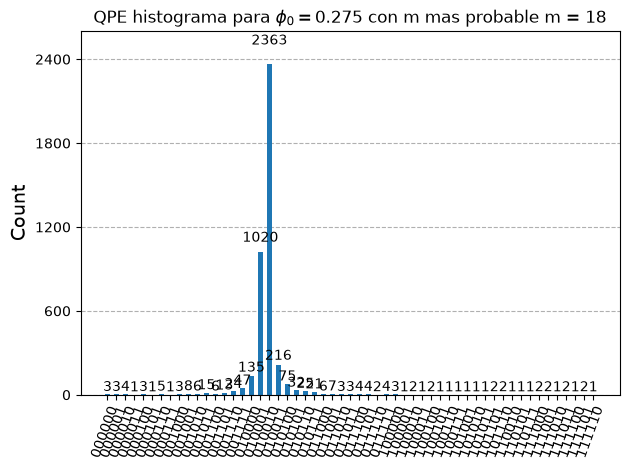

Fase estimada = 0.28125 con error = 0.006249999999999978


In [82]:
# Autovector |0>
qc0 = QuantumCircuit(t + 1, t)

qc0.h(range(t))

for i in range(t - 1, -1, -1):
    qc0.append(c_U_gate(phi0, phi1, 2**i), [i, t])

qc0.append(QFTGate(t).inverse(), range(t))

qc0.measure(range(t), range(t))
#display(qc0.draw('mpl'))
counts = sim.run(transpile(qc0, sim), shots = shots).result().get_counts()
m0 = max(counts, key = counts.get)
display(plot_histogram(counts, title = fr'QPE histograma para $\phi_0 = 0.275$ con m mas probable m = {int(m0, 2)}'))
estimated_phase0 = int(m0, 2)/2**t
error0 = abs(phi0 - estimated_phase0)
print(fr'Fase estimada = {estimated_phase0} con error = {error0}')


011000


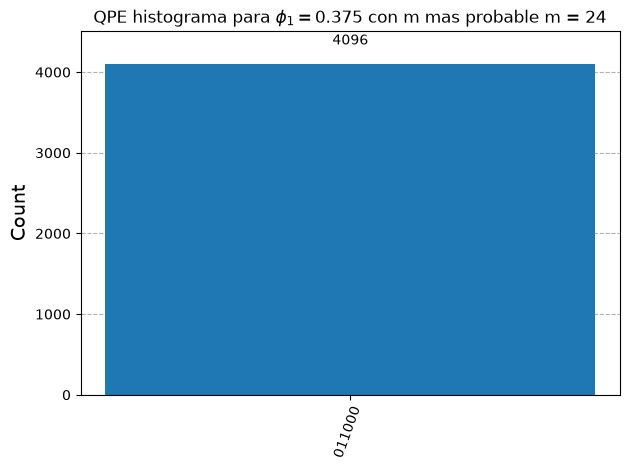

Fase estimada = 0.375 con error = 0.0


In [83]:
# Autovector |1>
qc1 = QuantumCircuit(t + 1, t)
qc1.x(t) # Preparo el autovector |1> en el qubit t

qc1.h(range(t))

for i in range(t - 1, -1, -1):
    qc1.append(c_U_gate(phi0, phi1, 2**i), [i, t])

qc1.append(QFTGate(t).inverse(), range(t))

qc1.measure(range(t), range(t))
#display(qc1.draw('mpl'))
counts = sim.run(transpile(qc1, sim), shots = shots).result().get_counts()
m1 = max(counts, key = counts.get)
print(m1)
display(plot_histogram(counts, title = fr'QPE histograma para $\phi_1 = 0.375$ con m mas probable m = {int(m1, 2)}'))
estimated_phase1 = int(m1, 2)/2**t
error1 = abs(phi1 - estimated_phase1)
print(fr'Fase estimada = {estimated_phase1} con error = {error1}')

### **Ejerciciio E2.4. Combinación lineal de autovectores**

In [84]:
phi0 = 0.275
phi1 = 0.375
t = 6

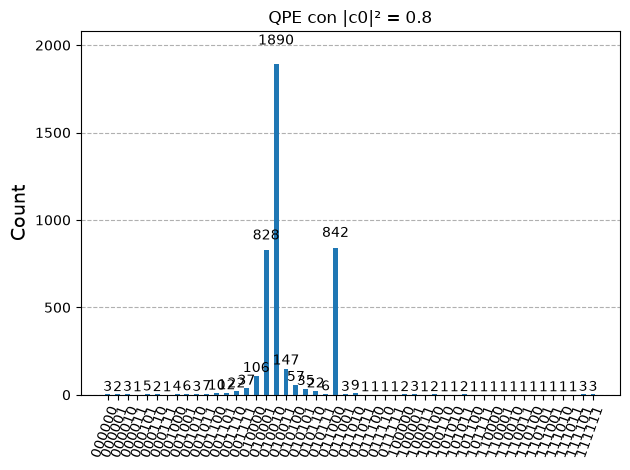

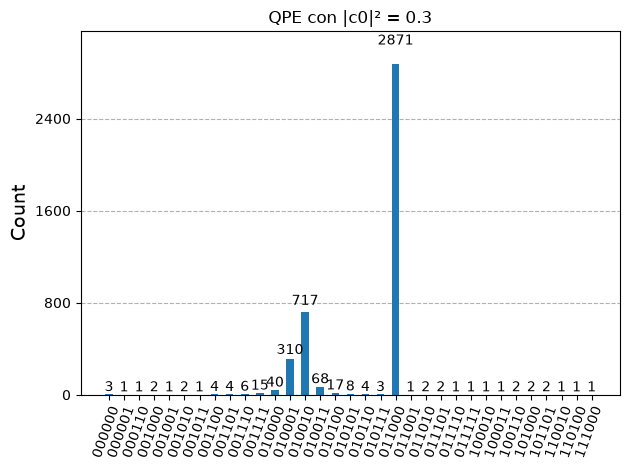

In [85]:
def qpe_psi(p0, medir_psi=False):
    theta = 2 * np.arccos(np.sqrt(p0))
    qc = QuantumCircuit(t + 1, t + 1 if medir_psi else t)
    qc.ry(theta, t)                    # |psi> = c0|0> + c1|1> en el qubit t
    qc.h(range(t))
    for i in range(t):
        qc.append(c_U_gate(phi0, phi1, 2**i), [i, t])   # tu c_U_gate del E2.3
    qc.append(QFTGate(t).inverse(), range(t))
    qc.measure(range(t), range(t))
    if medir_psi:
        qc.measure(t, t)               # para el apartado c)
    return qc

for p0 in (0.8, 0.3):
    counts = sim.run(transpile(qpe_psi(p0), sim), shots=shots).result().get_counts()
    display(plot_histogram(counts, title=f"QPE con |c0|² = {p0}"))

In [86]:
def prob_qpe(m, phi):
    k = np.arange(2**t)
    amp = np.exp(2j * np.pi * k * (phi - m / 2**t)).sum() / 2**t
    return abs(amp) ** 2

def prediccion(p0):
    return {format(m, f"0{t}b"): p0 * prob_qpe(m, phi0) + (1 - p0) * prob_qpe(m, phi1)
            for m in range(2**t)}

p0 = 0.8
counts = sim.run(transpile(qpe_psi(p0), sim), shots=shots).result().get_counts()
pred = prediccion(p0)
for m in (17, 18, 24):
    s = format(m, f"0{t}b")
    print(f"m={m}: observado {counts.get(s, 0)/shots:.3f}, predicho {pred[s]:.3f}")

m=17: observado 0.202, predicho 0.204
m=18: observado 0.461, predicho 0.458
m=24: observado 0.206, predicho 0.202


In [87]:
p1 = 0.3
counts = sim.run(transpile(qpe_psi(p1), sim), shots=shots).result().get_counts()
pred = prediccion(p1)
for m in (17, 18, 24):
    s = format(m, f"0{t}b")
    print(f"m={m}: observado {counts.get(s, 0)/shots:.3f}, predicho {pred[s]:.3f}")

m=17: observado 0.076, predicho 0.076
m=18: observado 0.175, predicho 0.172
m=24: observado 0.701, predicho 0.701
